Test de différentes méthodes pour traiter mes images : ouverture, fermeture et maxpool sur des batchs de pixels

In [4]:
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision import transforms
import matplotlib.pyplot as plt

In [5]:
PIL_to_tensor = transforms.ToTensor()

In [6]:
img = Image.open("data/dataset/test/EMSR207/AOI01/EMSR207_AOI01_02/EMSR207_AOI01_02_GRA.png")
img_tensor = PIL_to_tensor(img)
img_tensor = img_tensor.view(1, *img_tensor.shape)

In [7]:
print(img_tensor.shape)  # Affiche la forme du tenseur

torch.Size([1, 3, 1442, 1973])


In [8]:
def dilation(x, kernel_size):
    # x : (N, 1, H, W), float tensor
    pad = kernel_size // 2
    x_padded = F.pad(x, (pad, pad, pad, pad), mode='replicate')
    return F.max_pool2d(x_padded, kernel_size, stride=1)

def erosion(x, kernel_size):
    # x : (N, 1, H, W), float tensor
    pad = kernel_size // 2
    x_padded = F.pad(x, (pad, pad, pad, pad), mode='replicate')
    return -F.max_pool2d(-x_padded, kernel_size, stride=1)

def opening(x, kernel_size):
    return dilation(erosion(x, kernel_size), kernel_size)

def closing(x, kernel_size):
    return erosion(dilation(x, kernel_size), kernel_size)





def mode_filter(mask, kernel_size):
    """
    mask : tensor (B, H, W), int64
    renvoie un tensor (B, H, W) lissé par mode filter
    """
    B, H, W = mask.shape
    pad = kernel_size // 2

    # One-hot encoding des classes
    n_classes = mask.max().item() + 1
    mask_onehot = F.one_hot(mask, num_classes=n_classes)  # (B,H,W,C)
    mask_onehot = mask_onehot.permute(0, 3, 1, 2).float()  # (B,C,H,W)

    # Padding
    mask_padded = F.pad(mask_onehot, (pad, pad, pad, pad), mode='replicate')

    # Extract patches
    unfolded = F.unfold(mask_padded, kernel_size=kernel_size)  # (B, C*kernel_size**2, H*W)
    unfolded = unfolded.view(B, n_classes, kernel_size**2, H, W)  # (B,C,K2,H,W)

    # Sum occurrences par classe
    counts = unfolded.sum(dim=2)  # (B,C,H,W)

    # Classe majoritaire
    mode_mask = counts.argmax(dim=1)  # (B,H,W)
    return mode_mask


In [14]:
def imgs_to_niveaucouleur(imgs):

    imgs = (imgs * 255).byte()

    imgs = imgs.permute(1, 0, 2, 3)   # (B, C, H, W) -> (C, B, H, W)

    colors = [[181, 254, 142], [254, 217, 142], [254, 153, 41], [204, 76, 2]]

    masks = []
    for c in colors:
        color_tensor = torch.tensor(c, dtype=imgs.dtype, device=imgs.device).view(-1, 1, 1, 1)
        mask = (imgs == color_tensor).all(dim=0)
        masks.append(mask)

    # # Combiner tous les masks
    # combined_mask = masks[0].clone()
    # for m in masks[1:]:
    #     combined_mask |= m  # ou “torch.logical_or(combined_mask, m)”

    # # Vérifier les pixels qui ne correspondent à aucune couleur
    # unknown_pixels = ~combined_mask
    # n_unknown = unknown_pixels.sum().item()

    # print(f"Nombre de pixels inconnus : {n_unknown}")


    # # appliquer un filtrage (ouverture puis fermeture (voir morphologie mathématique))
    # filtered_masks = []
    # for mask in masks:
    #     # les masques ont une shape (B, H, W)
    #     mask = opening(mask.unsqueeze(1).float(), kernel_size=5).squeeze(1).bool()
    #     mask = closing(mask.unsqueeze(1).float(), kernel_size=5).squeeze(1).bool()
    #     filtered_masks.append(mask)

    out = torch.zeros((imgs.shape[1], imgs.shape[2], imgs.shape[3]), dtype=torch.int64, device=imgs.device)
    for i, mask in enumerate(masks):
        out[mask] = i + 1

    # filtre médian
    # out = mode_filter(out, kernel_size=21)

    return out

In [15]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)        # For CUDA

In [16]:
crop = transforms.RandomCrop(size=(1442, 1973))
tensor = crop(img_tensor)
print(tensor.shape)

tensor = imgs_to_niveaucouleur(tensor).squeeze(0)
print(tensor.shape)

torch.Size([1, 3, 1442, 1973])
torch.Size([1442, 1973])


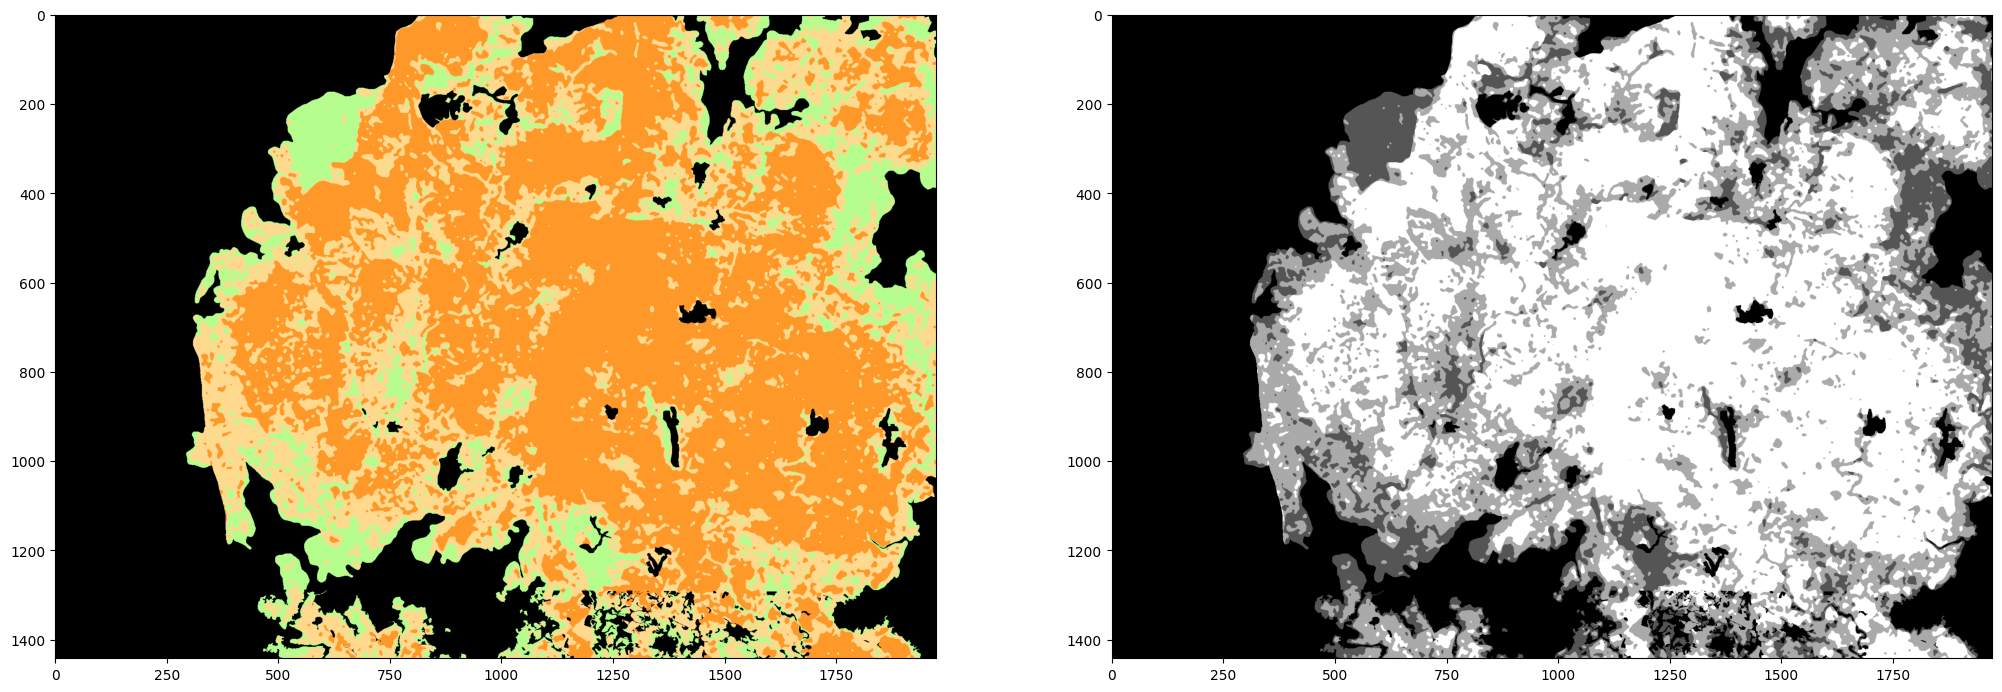

In [24]:
plt.figure(figsize=(25, 20))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.subplot(1, 2, 2)
plt.imshow(tensor.cpu().detach().numpy(), cmap='gray')
plt.show()

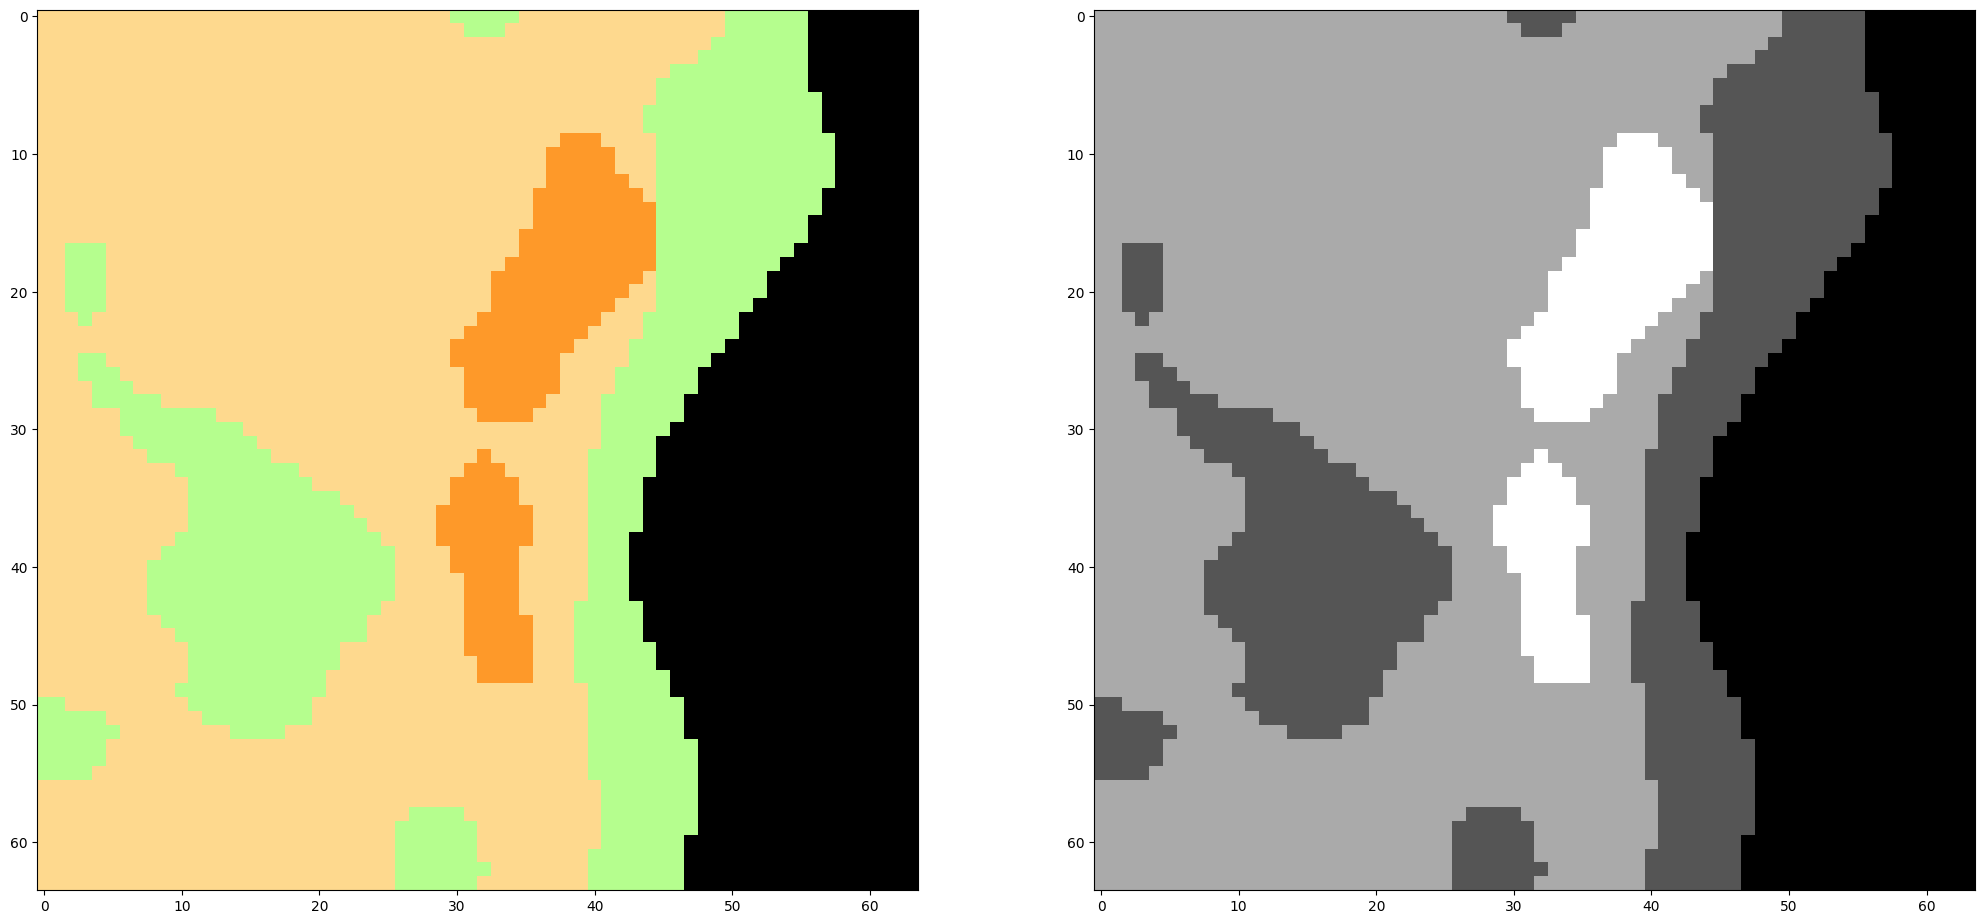

In [44]:
seed = 3

crop = transforms.RandomCrop(size=(64, 64))

torch.manual_seed(seed)
img_crop = crop(img)
torch.manual_seed(seed)
tensor_crop = crop(tensor)

tensor_crop = mode_filter(tensor_crop.unsqueeze(0), kernel_size=1).squeeze(0)

plt.figure(figsize=(25, 20))
plt.subplot(1, 2, 1)
plt.imshow(img_crop)
plt.subplot(1, 2, 2)
plt.imshow(tensor_crop.cpu().detach().numpy(), cmap='gray')
plt.show()

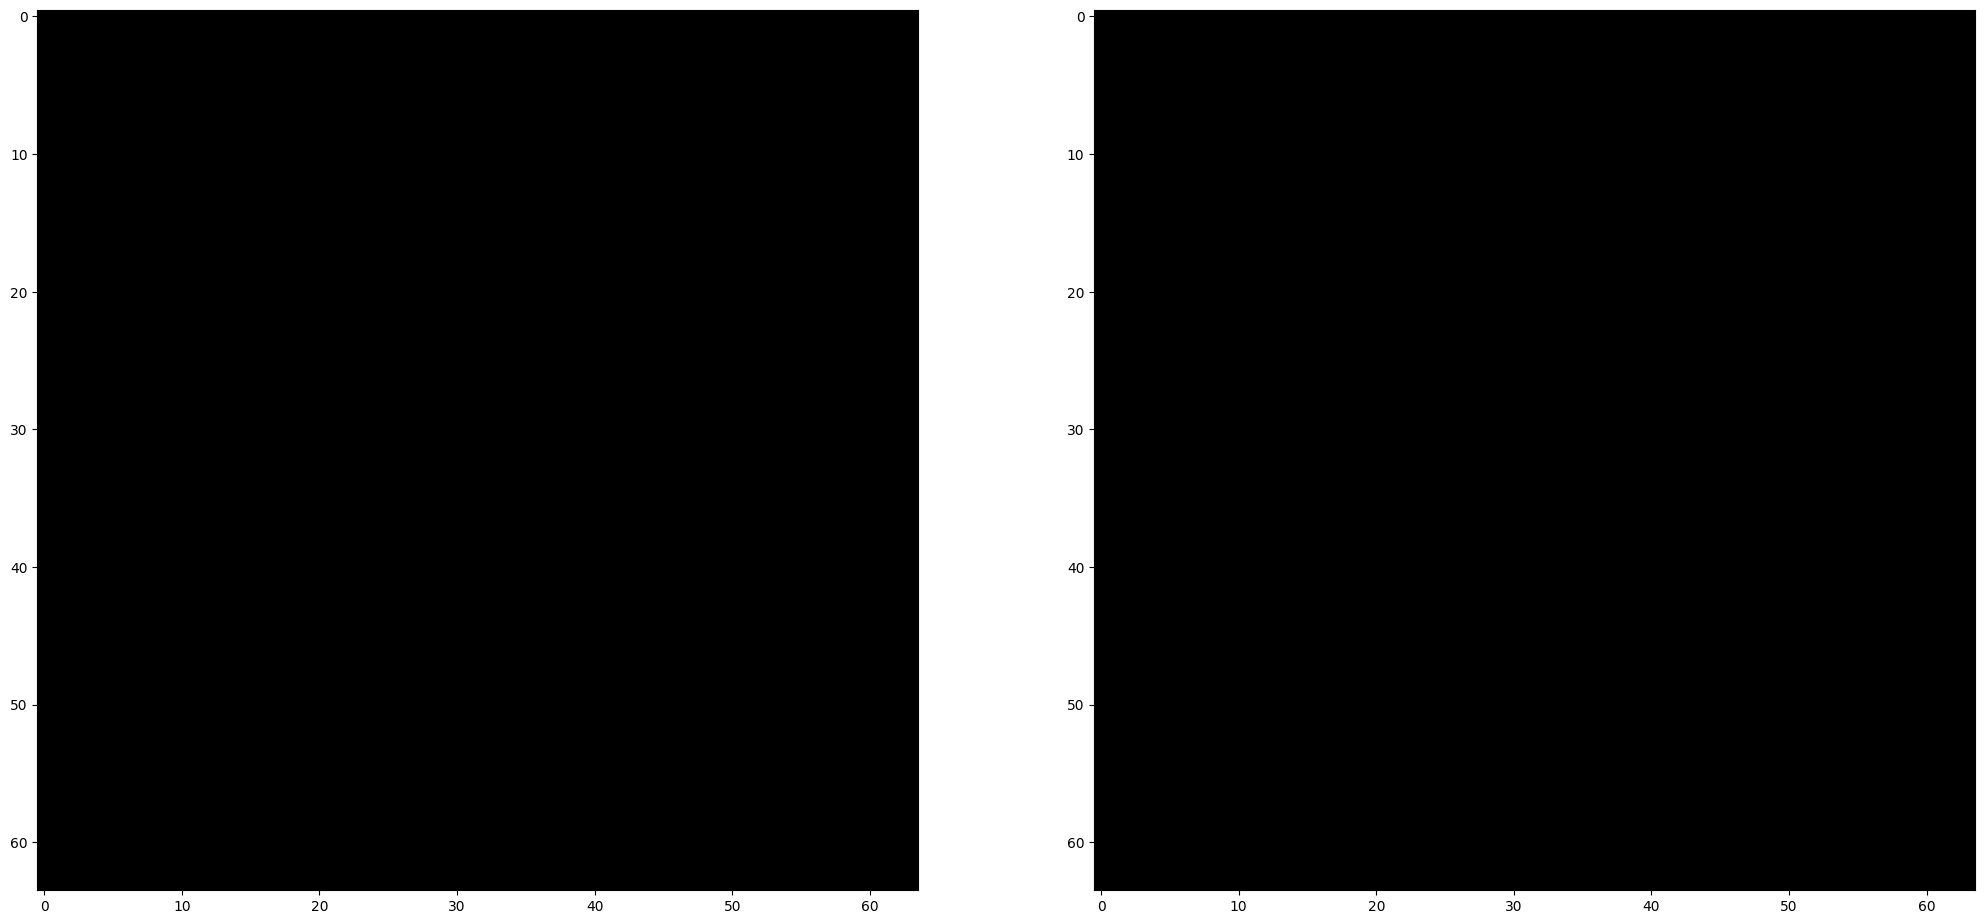

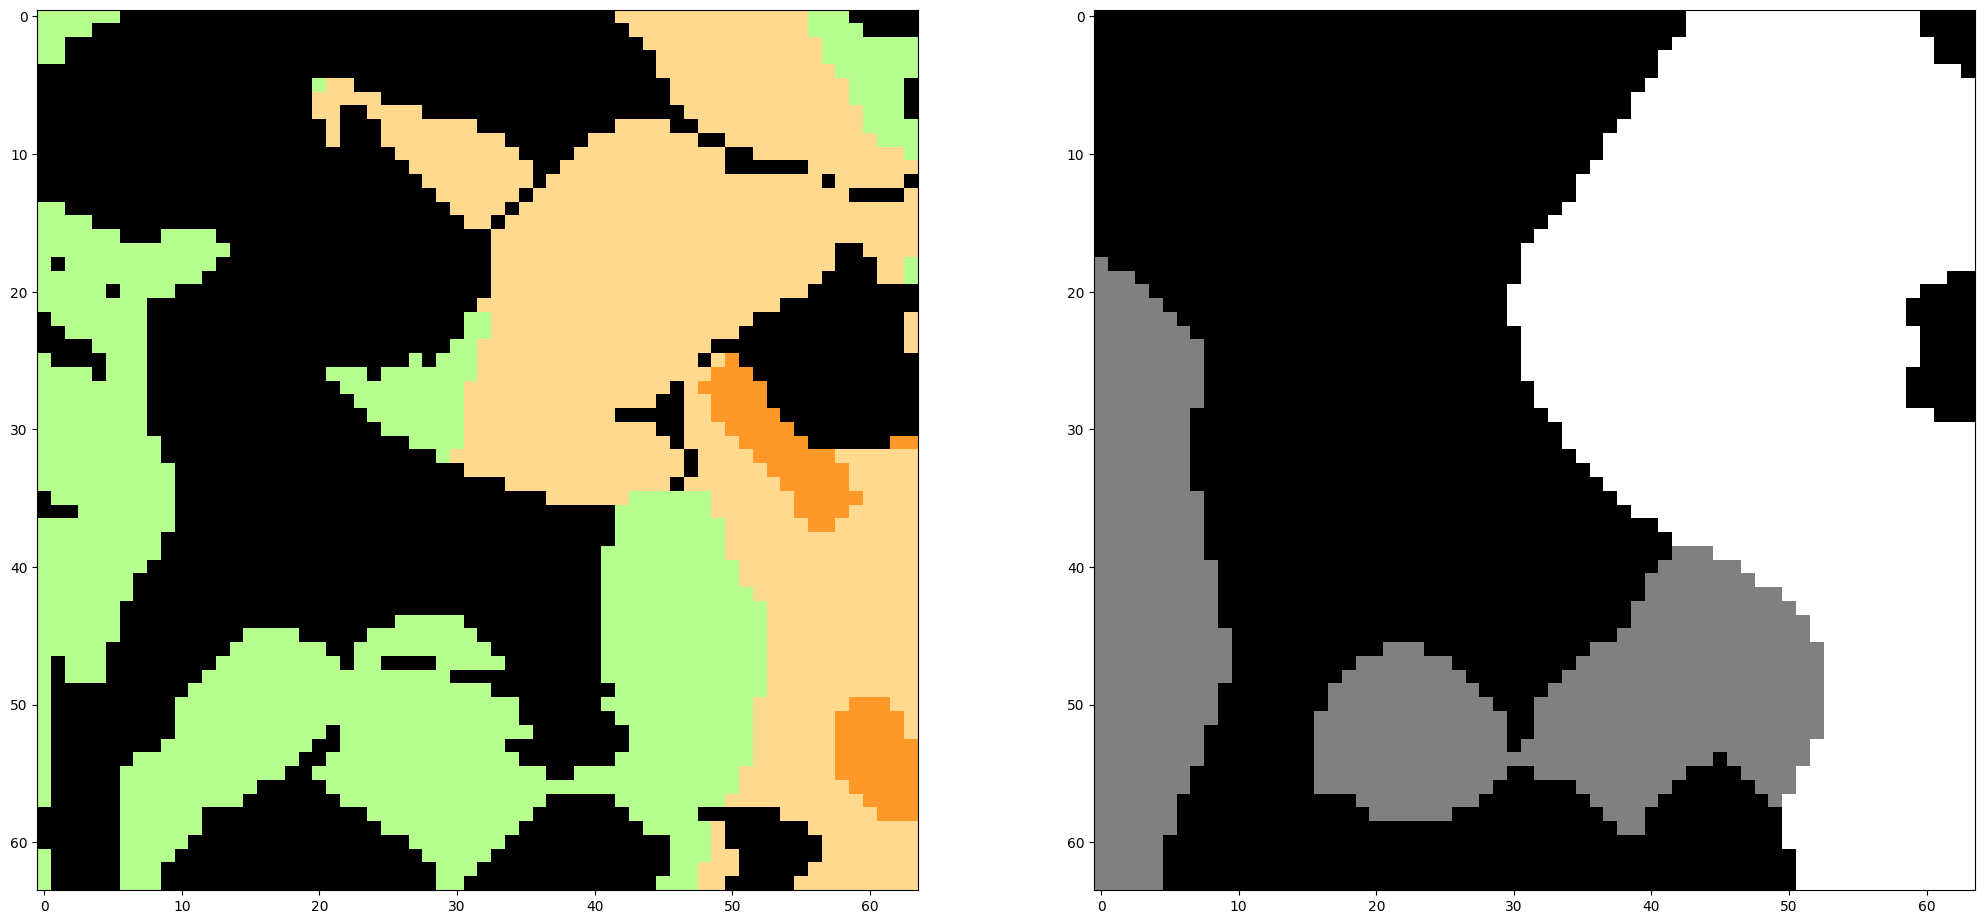

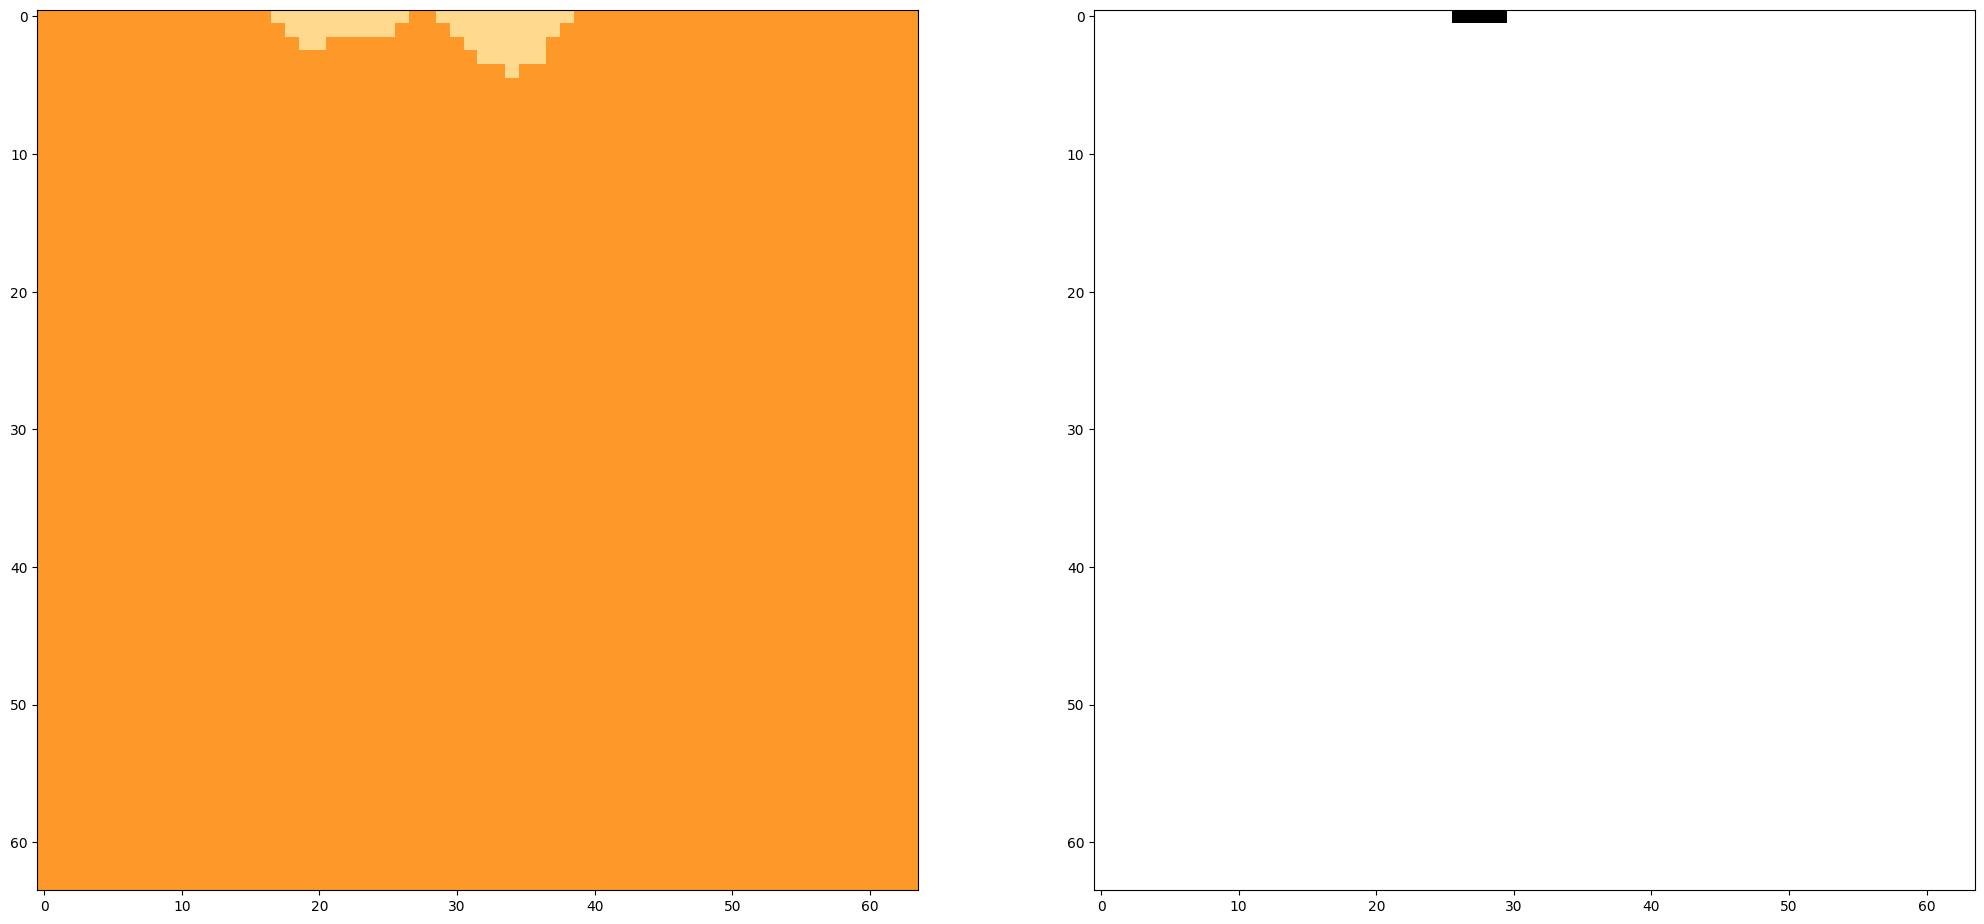

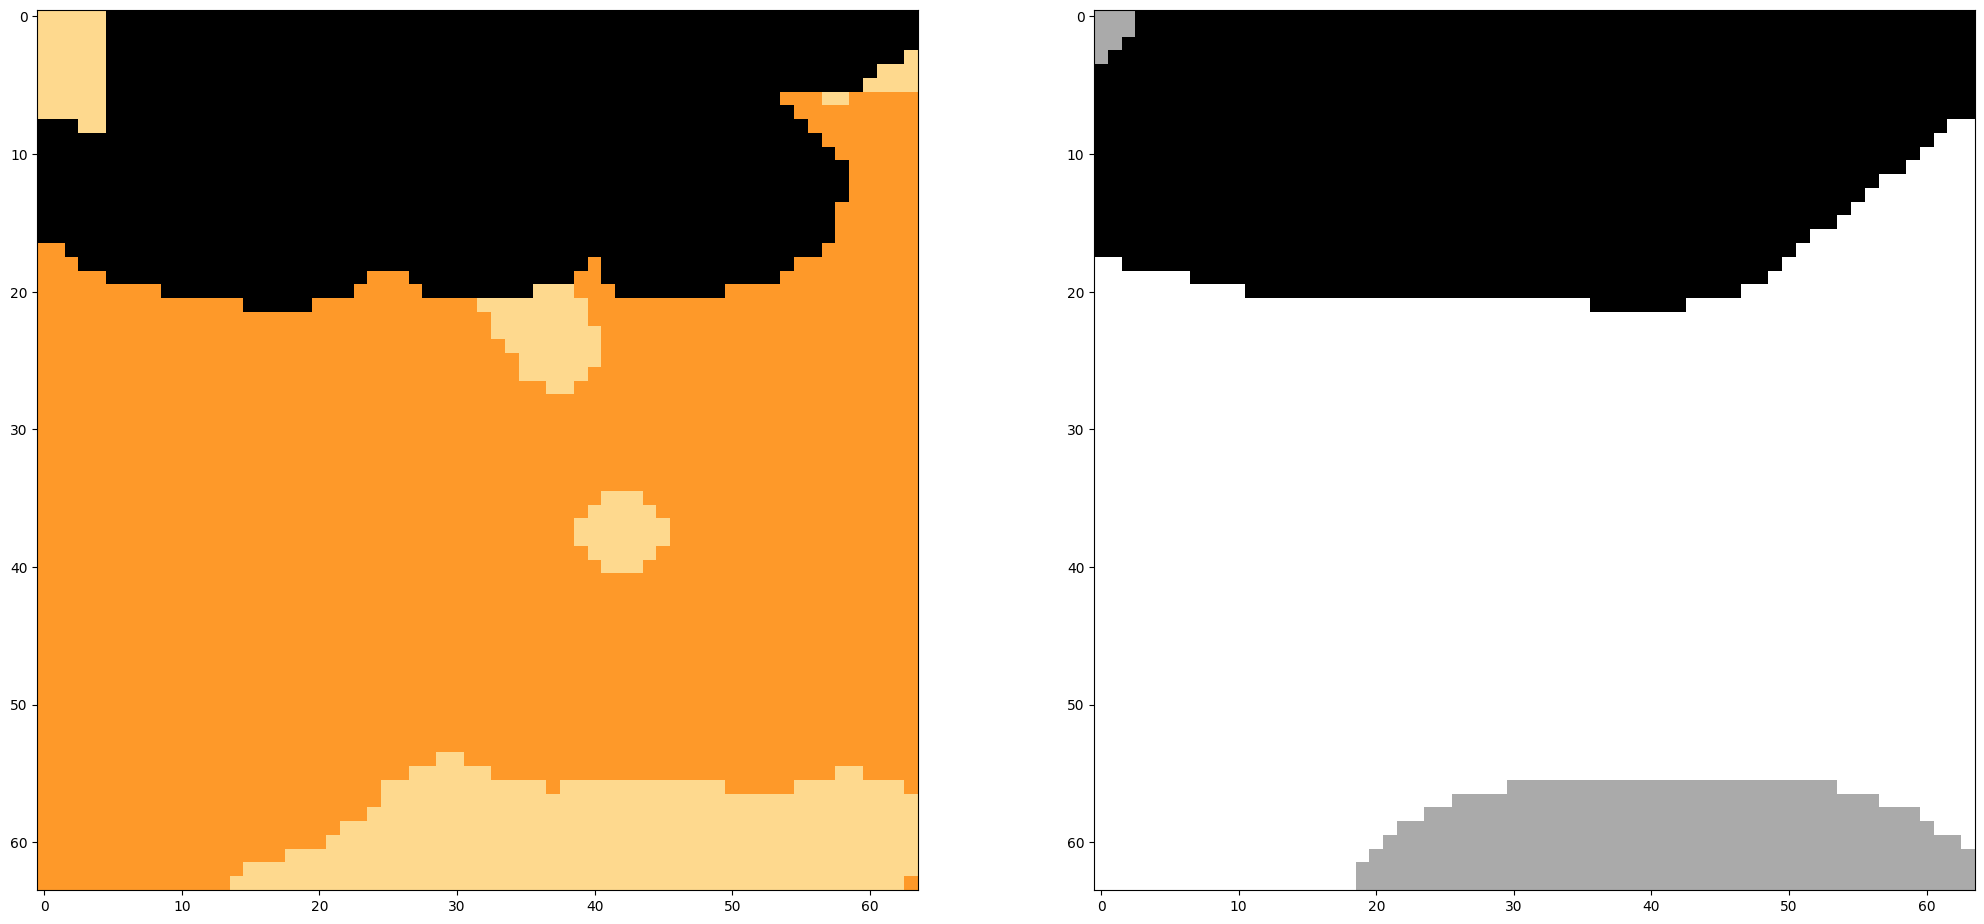

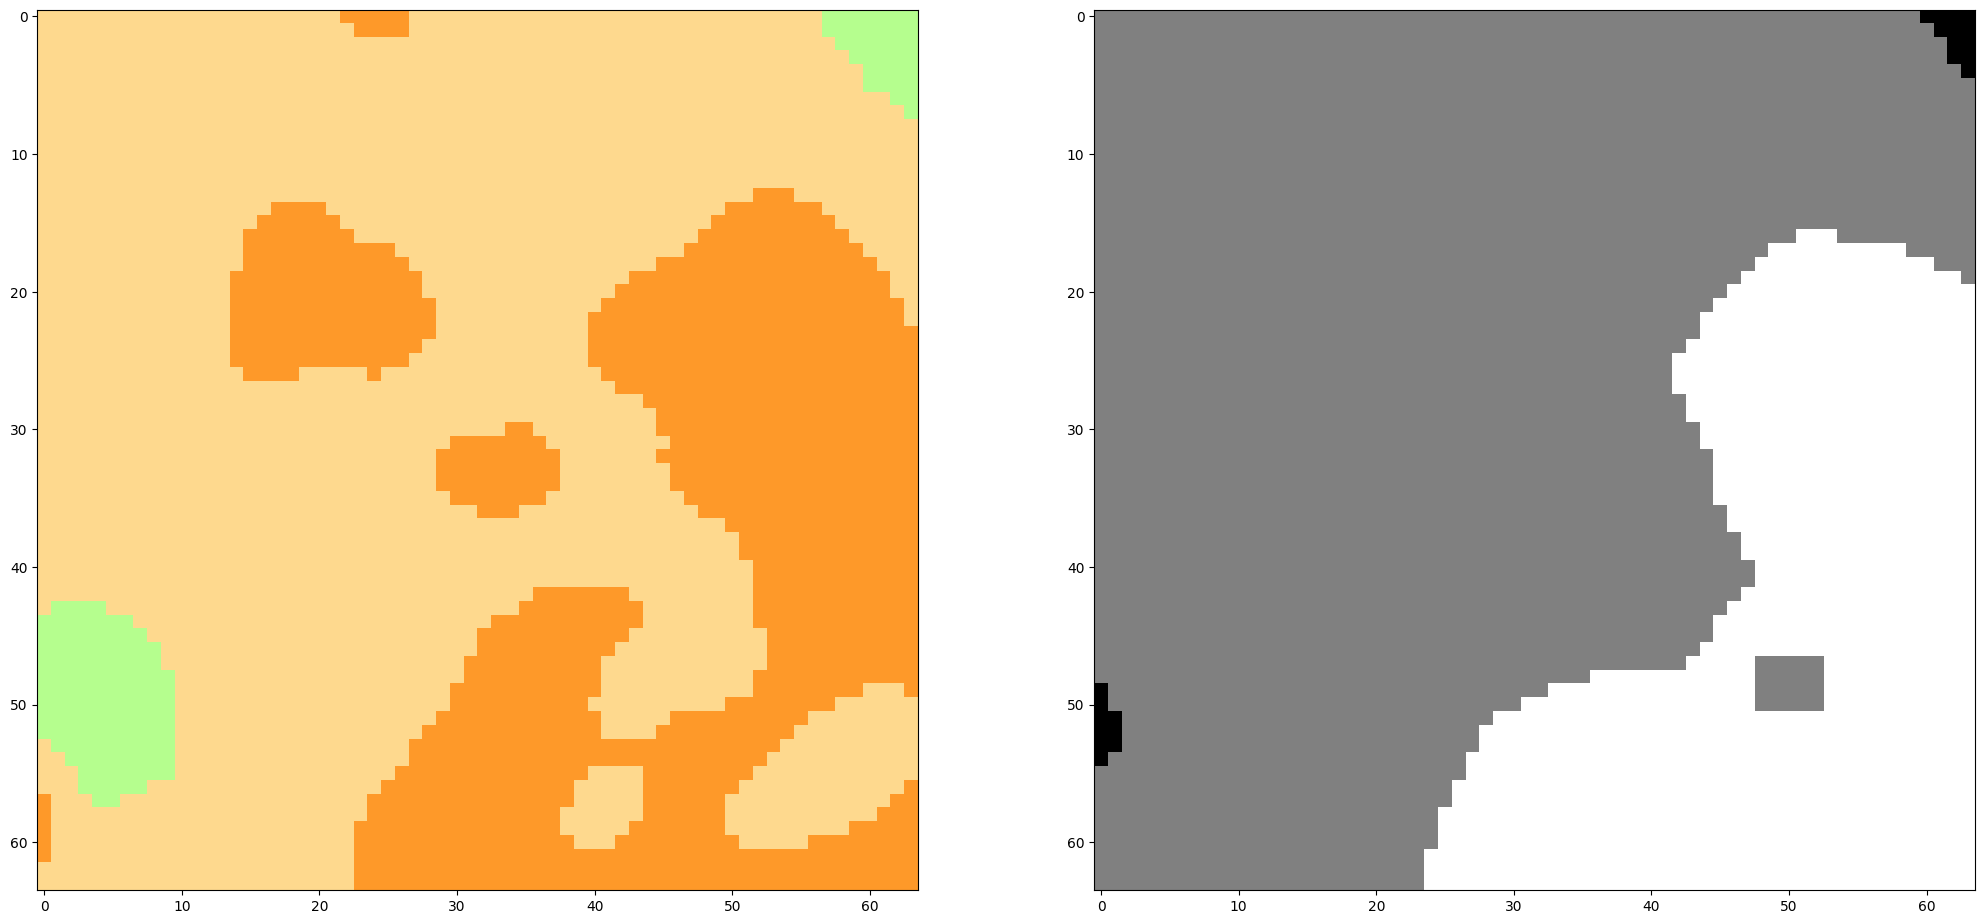

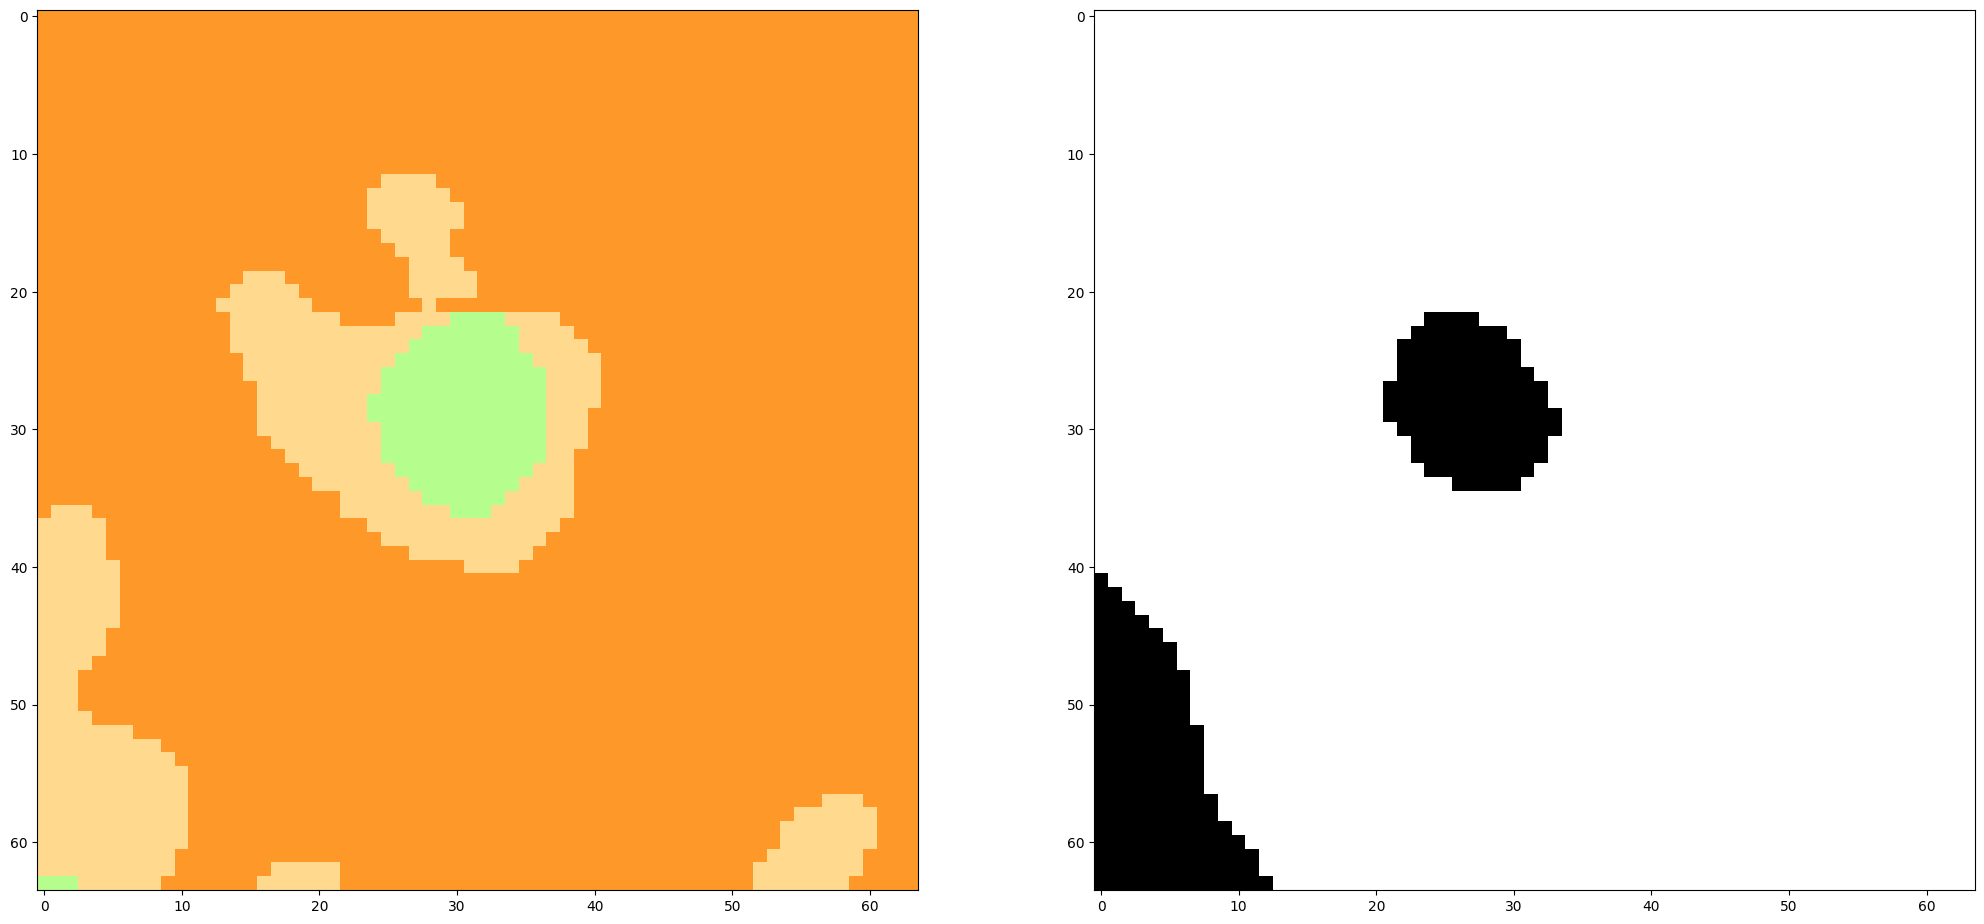

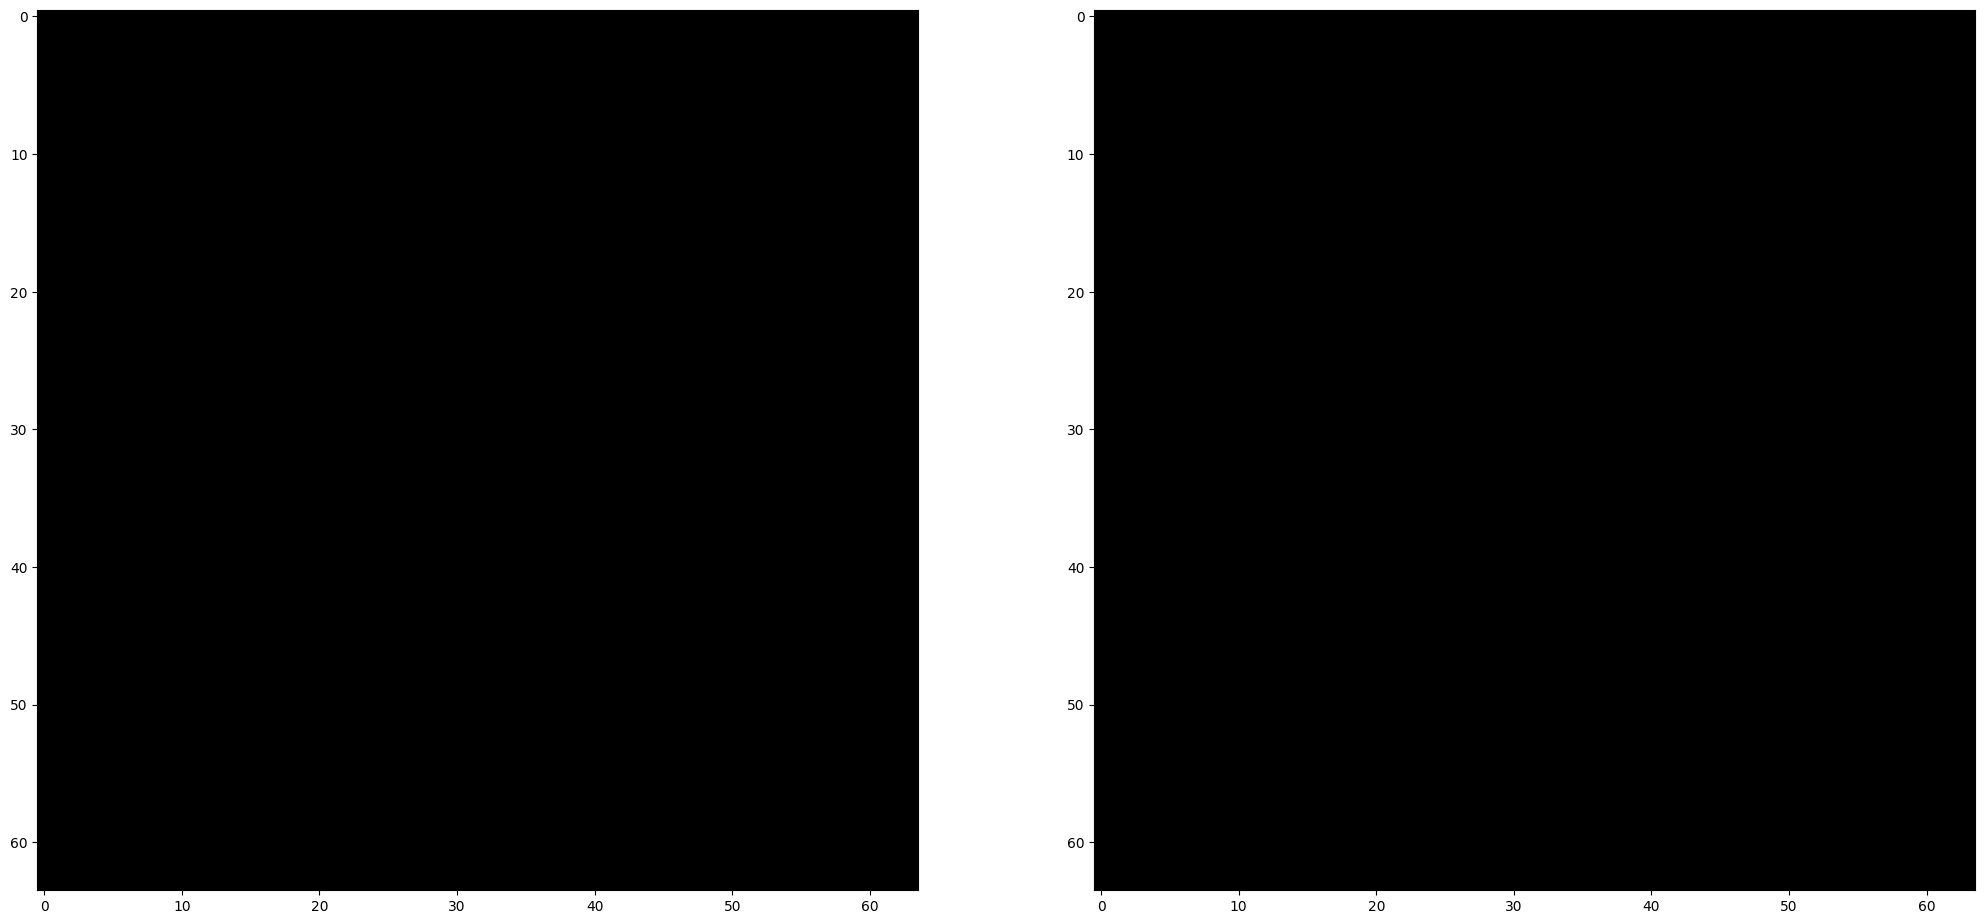

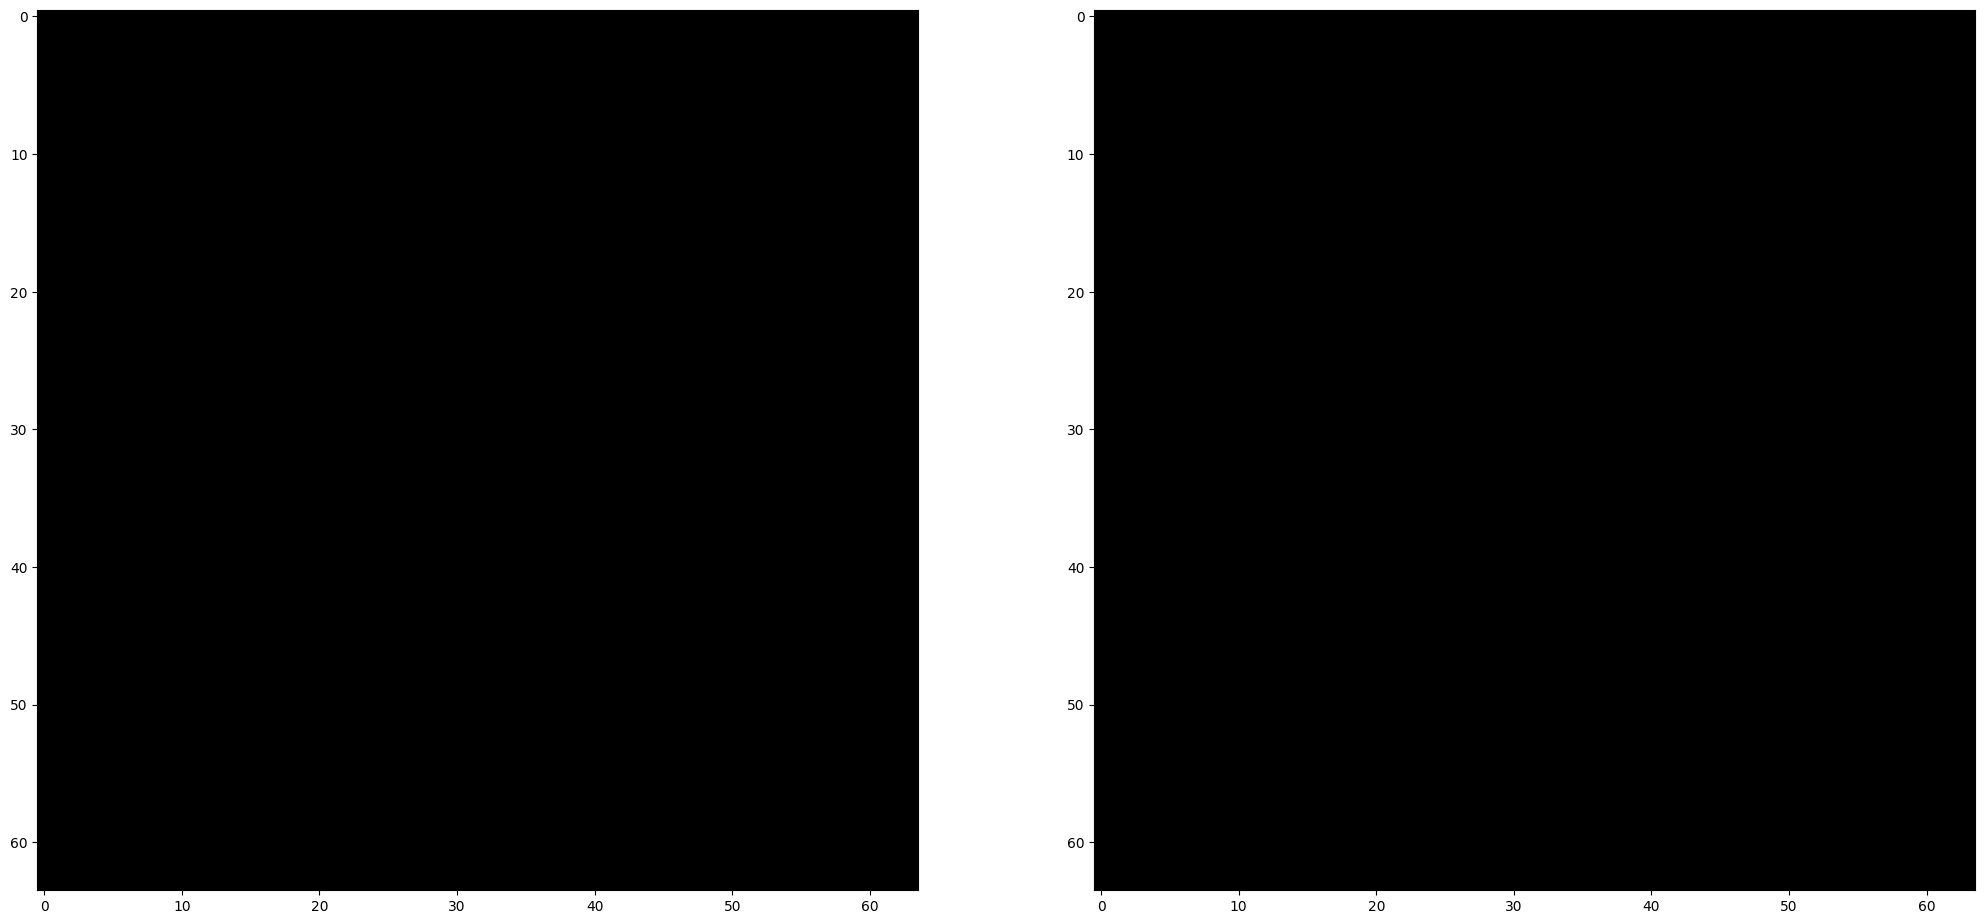

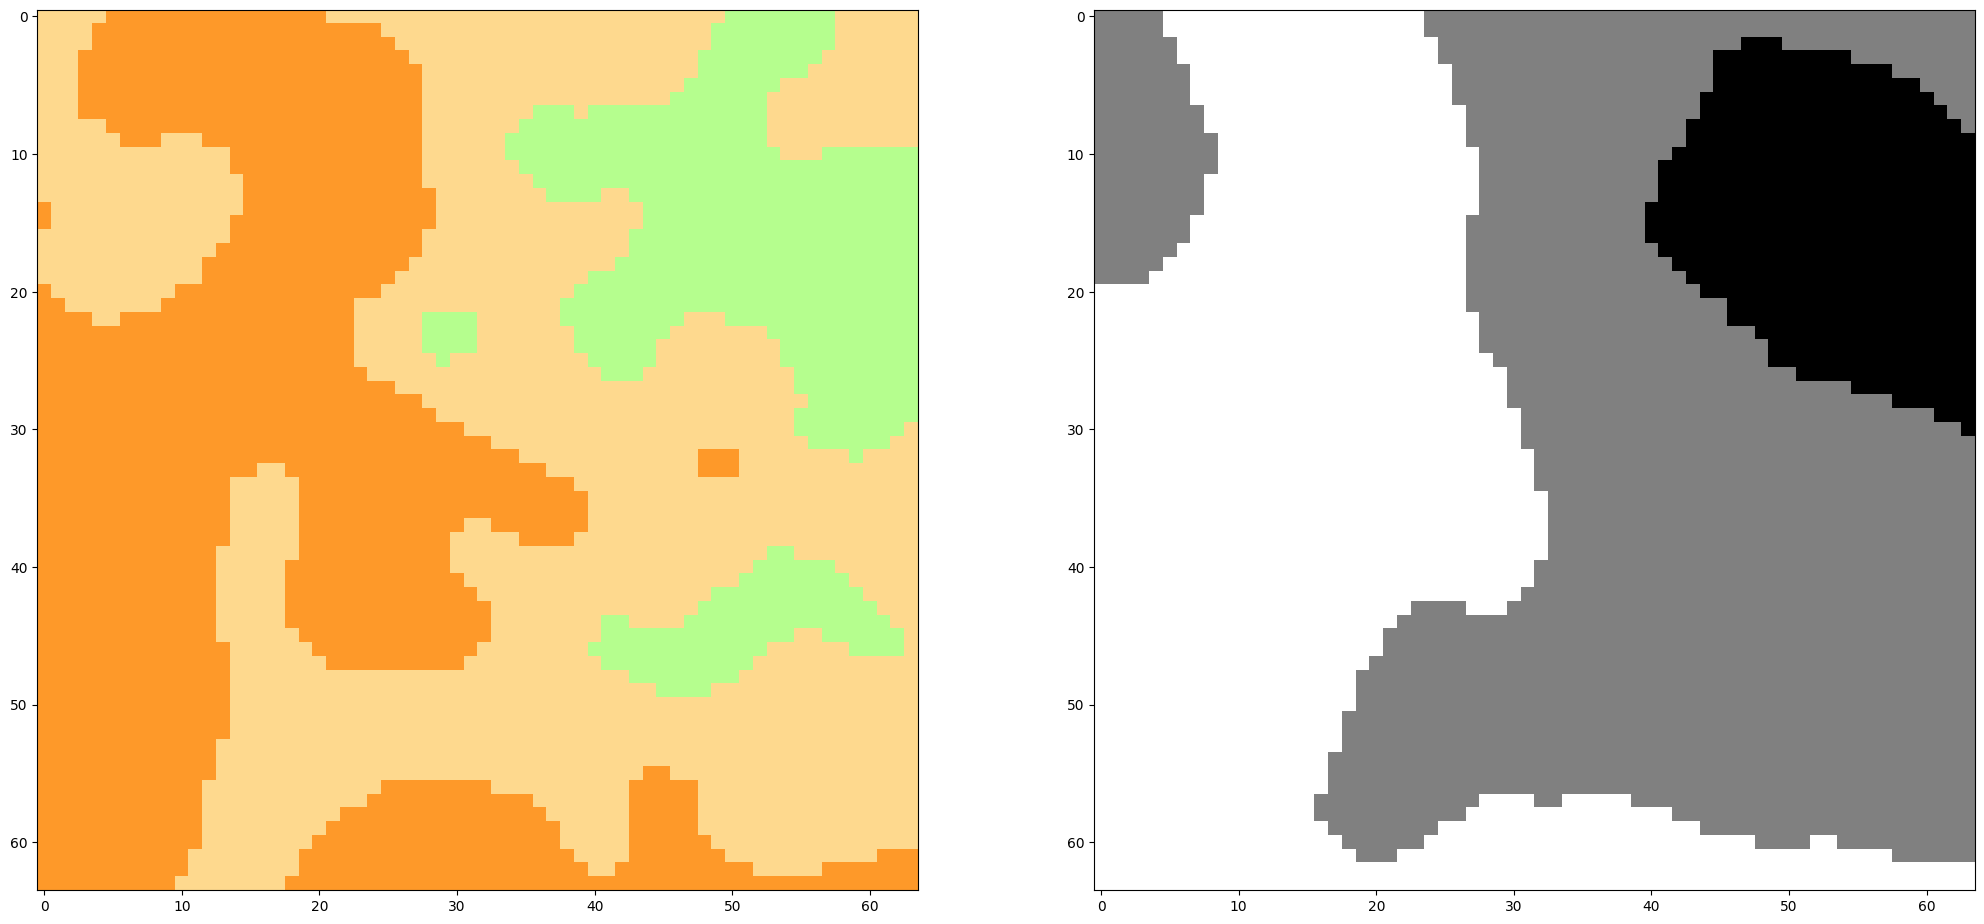

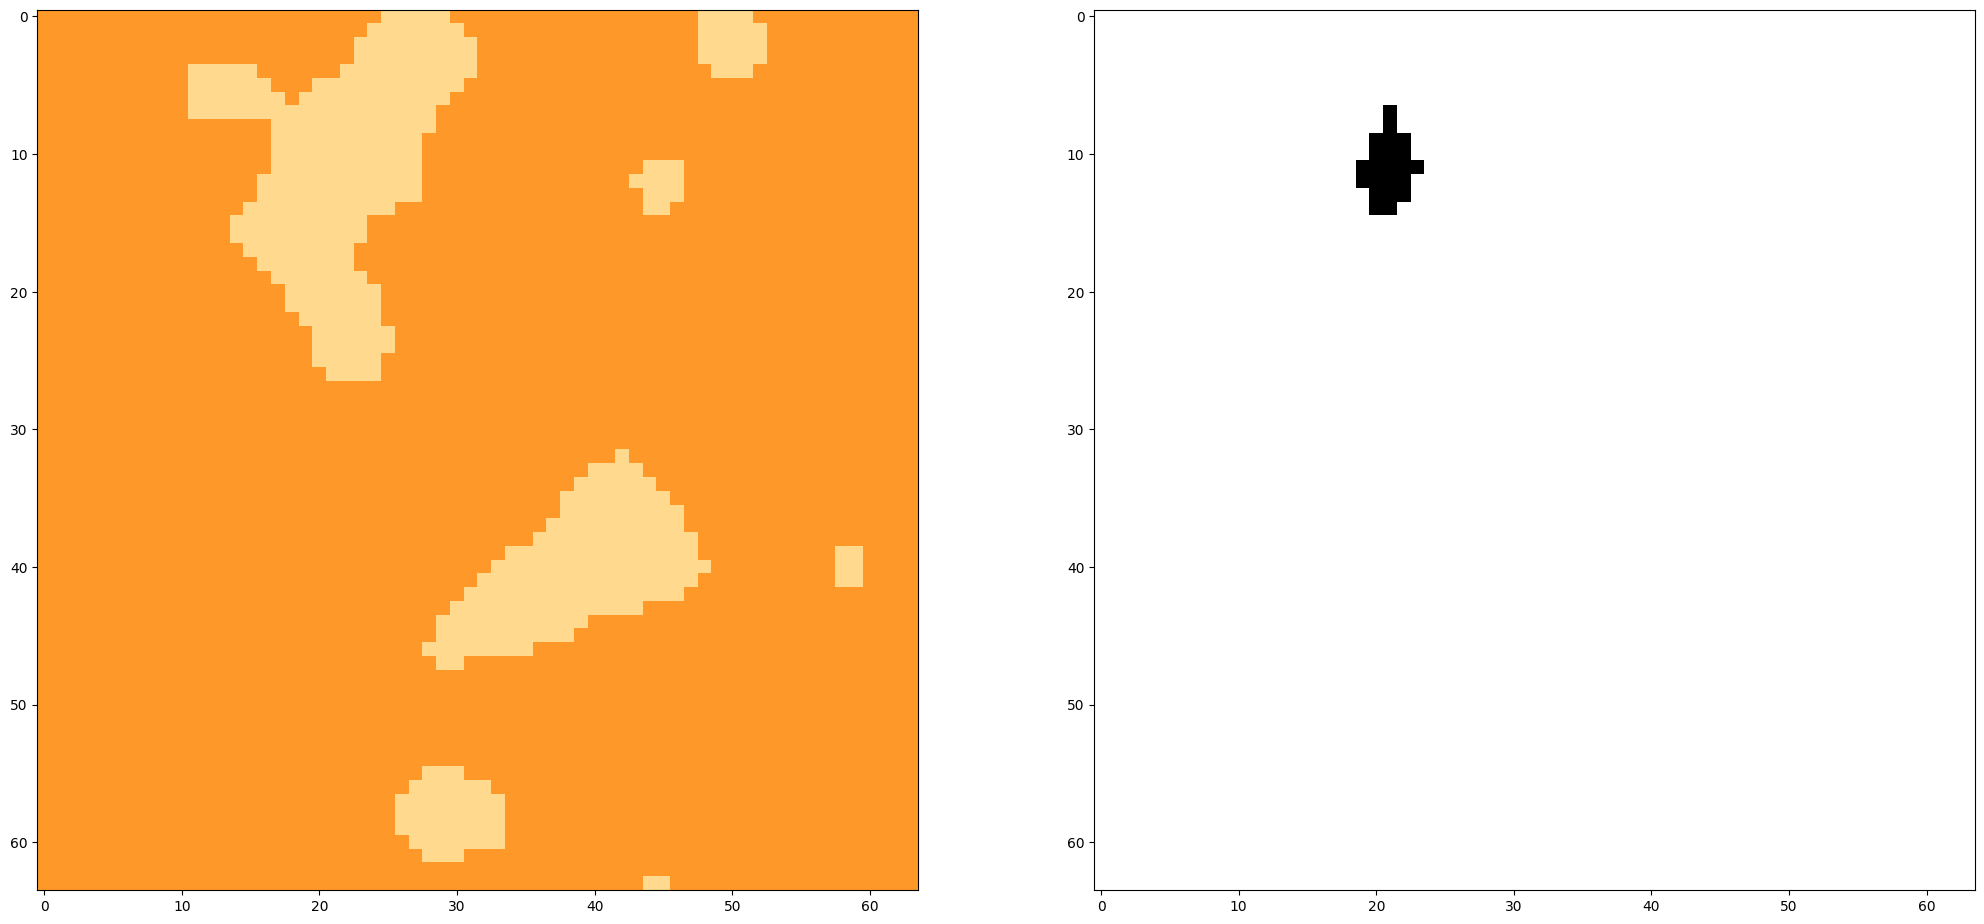

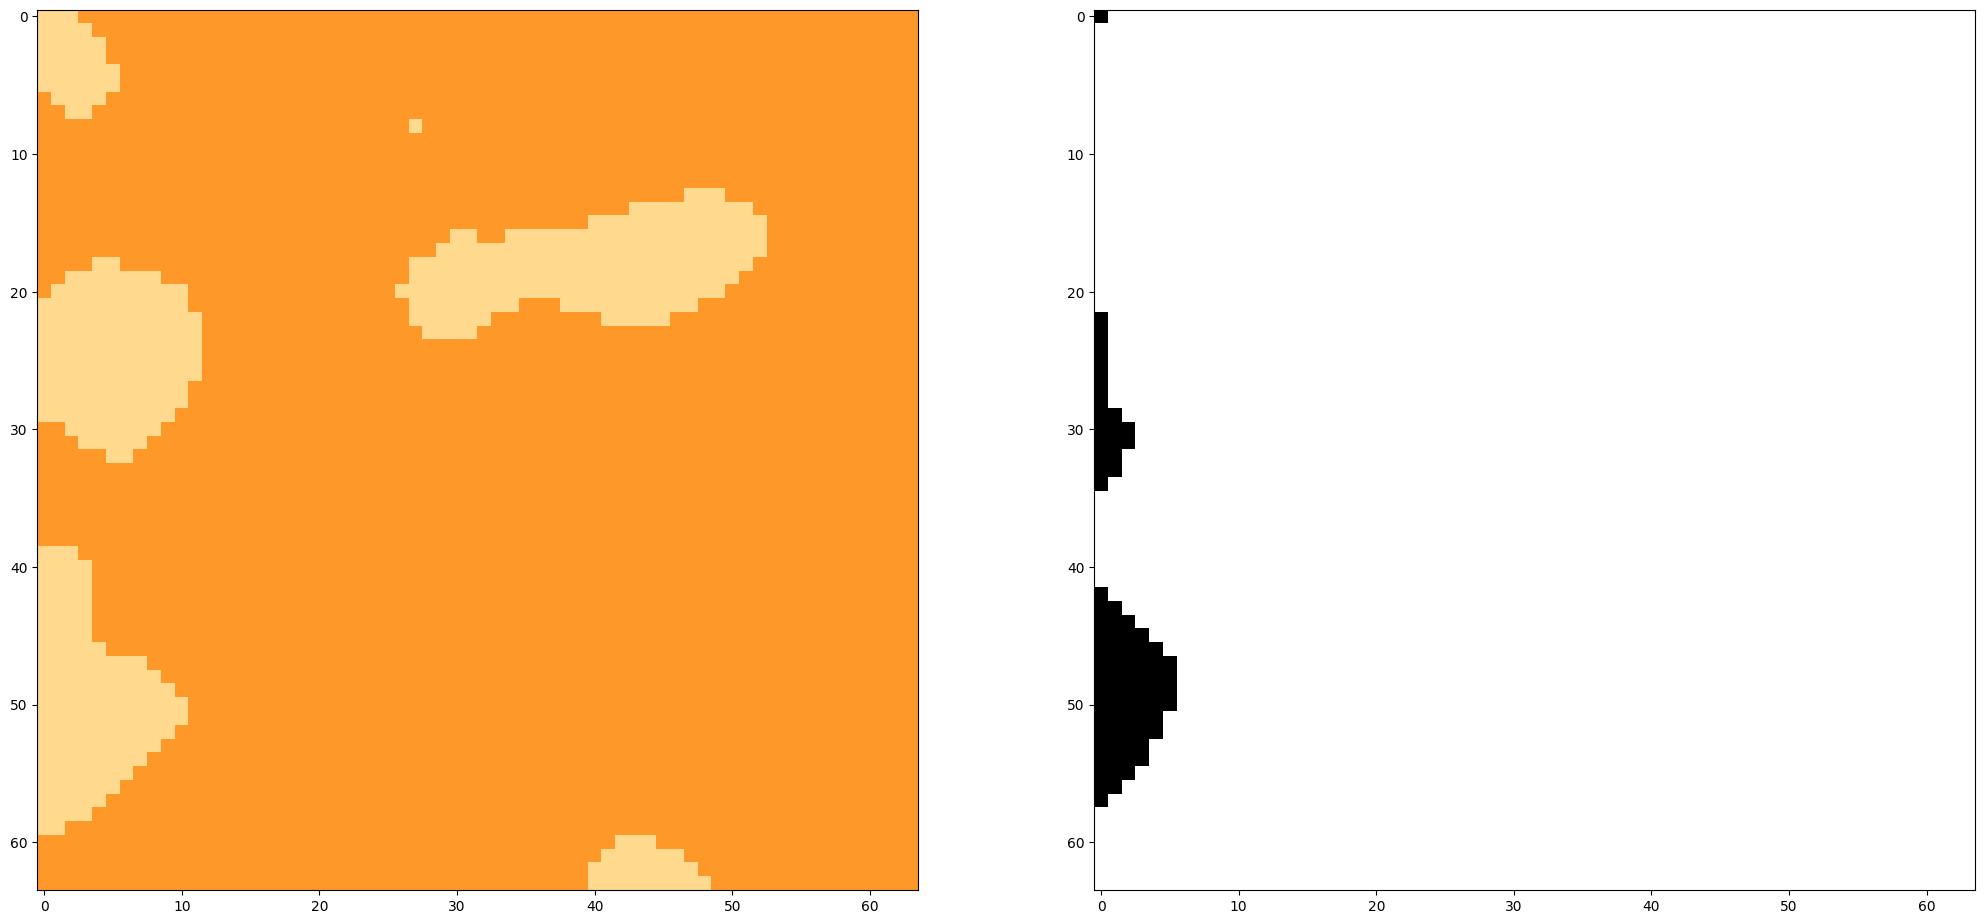

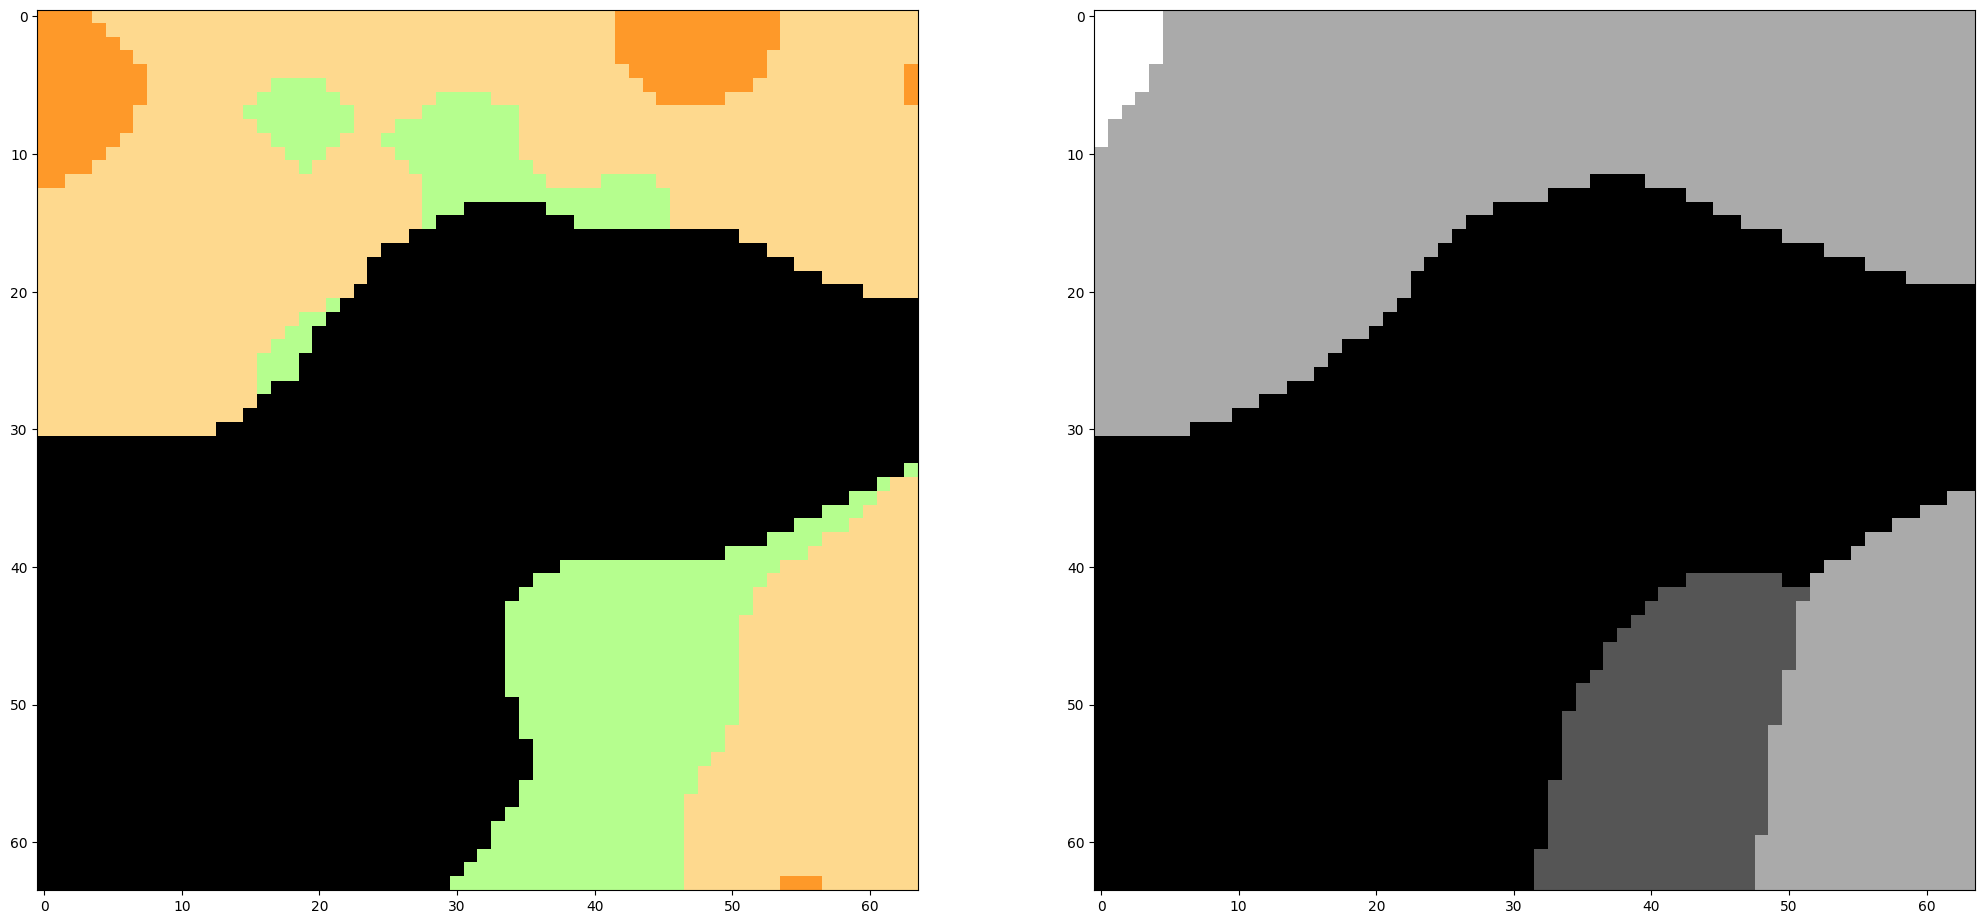

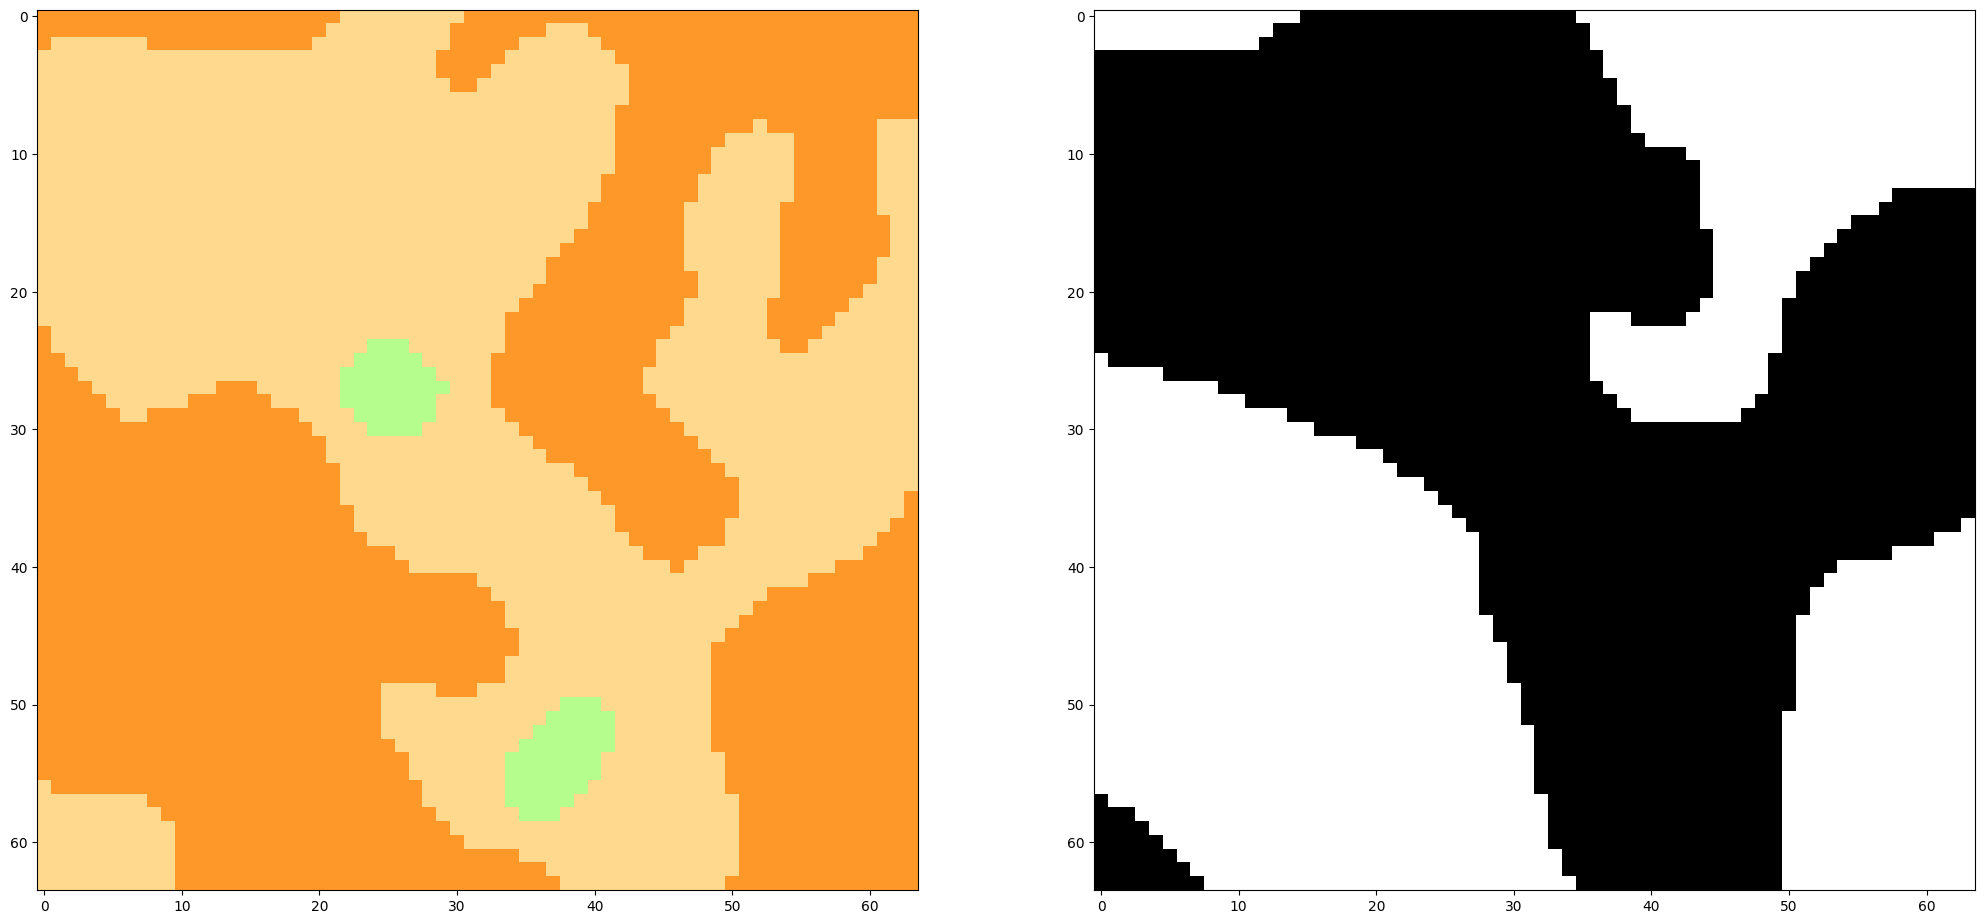

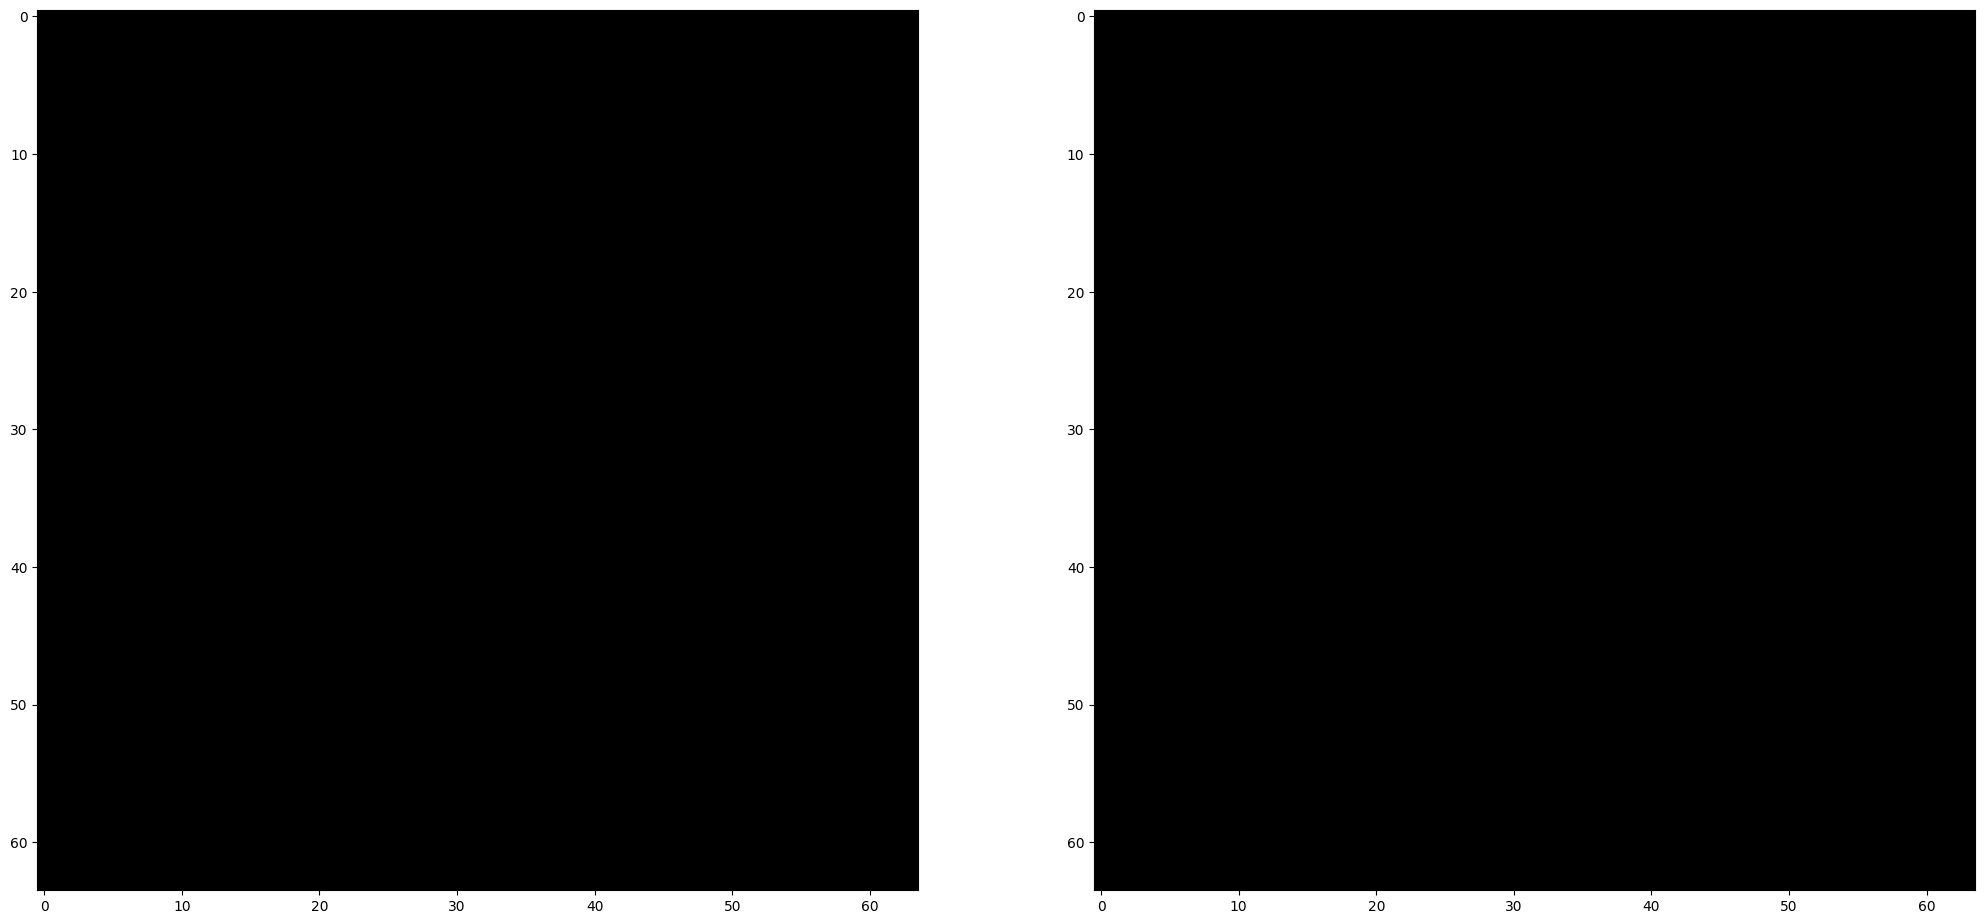

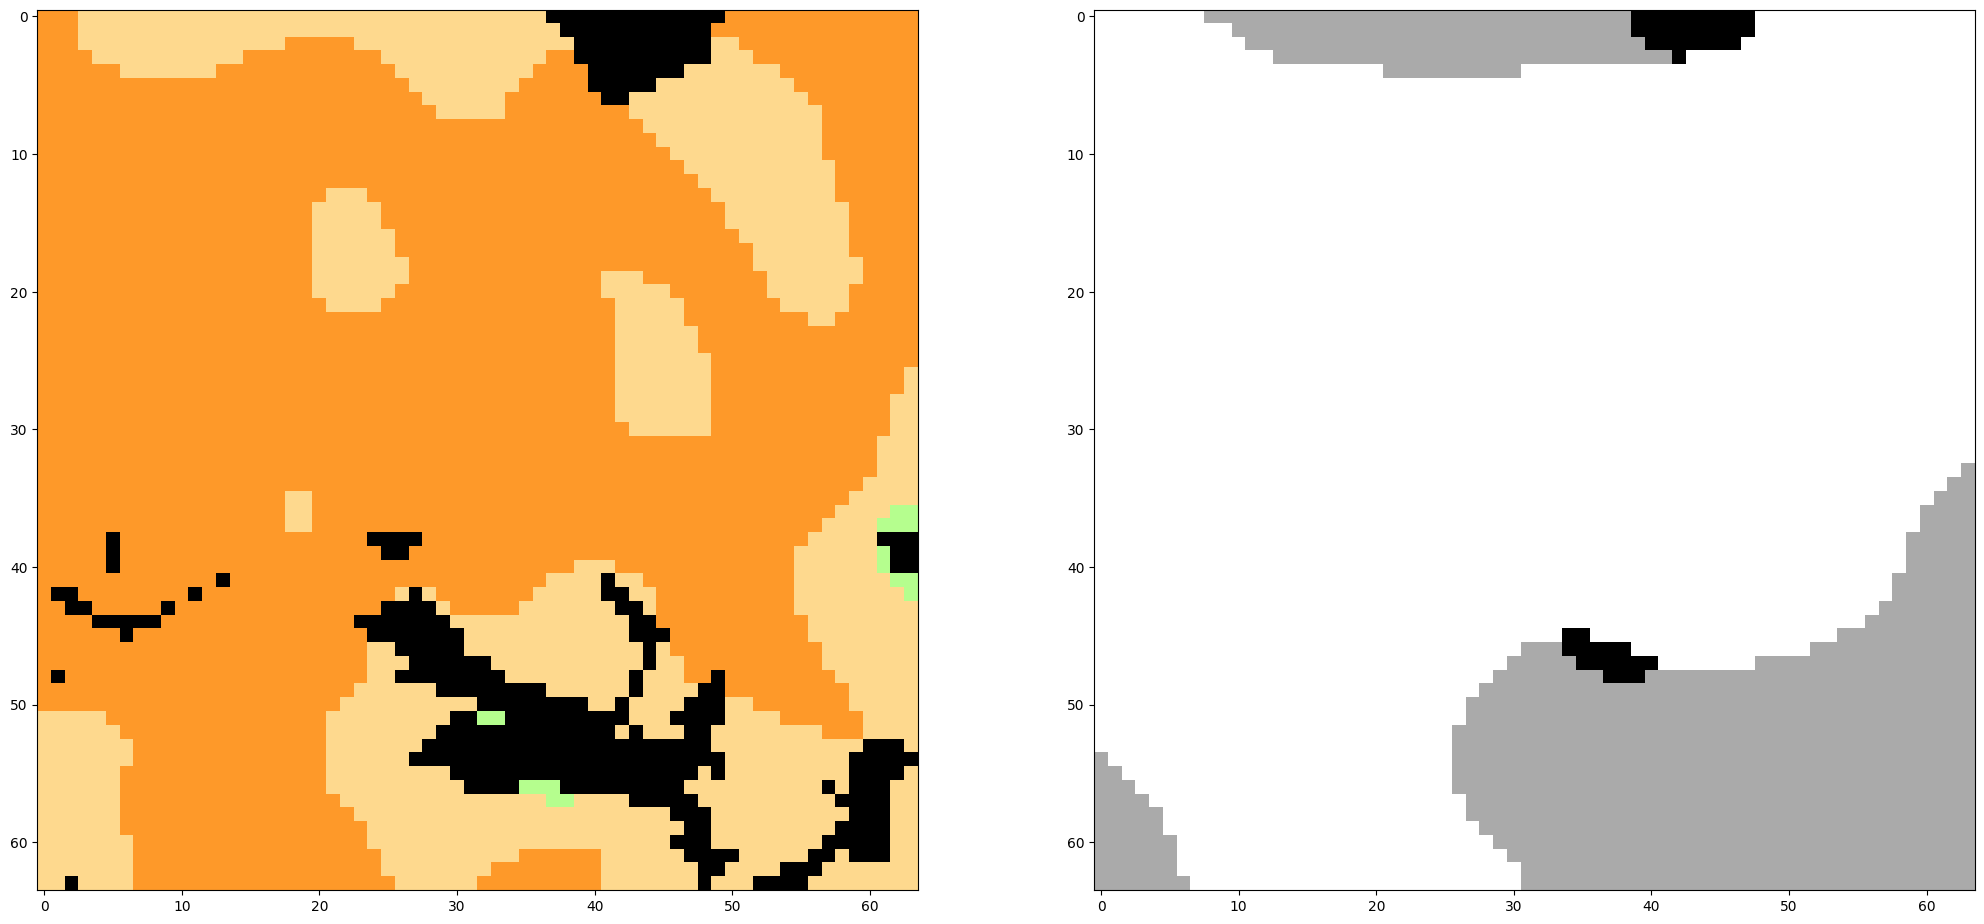

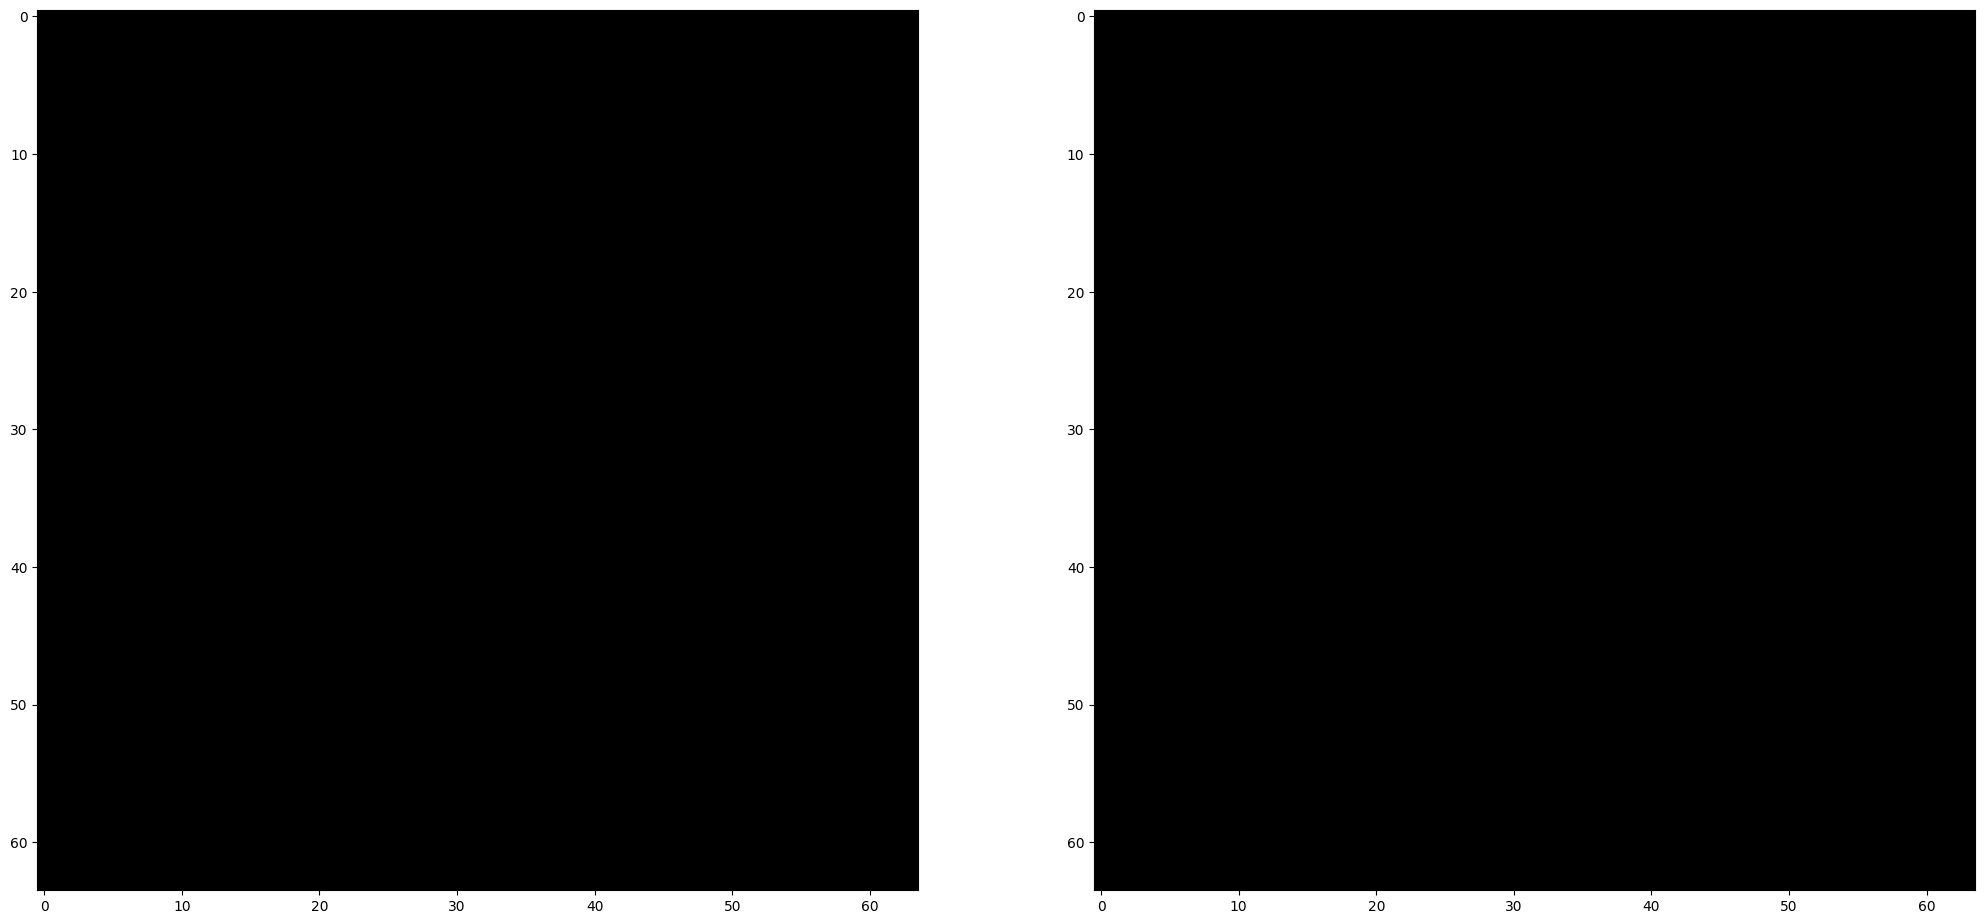

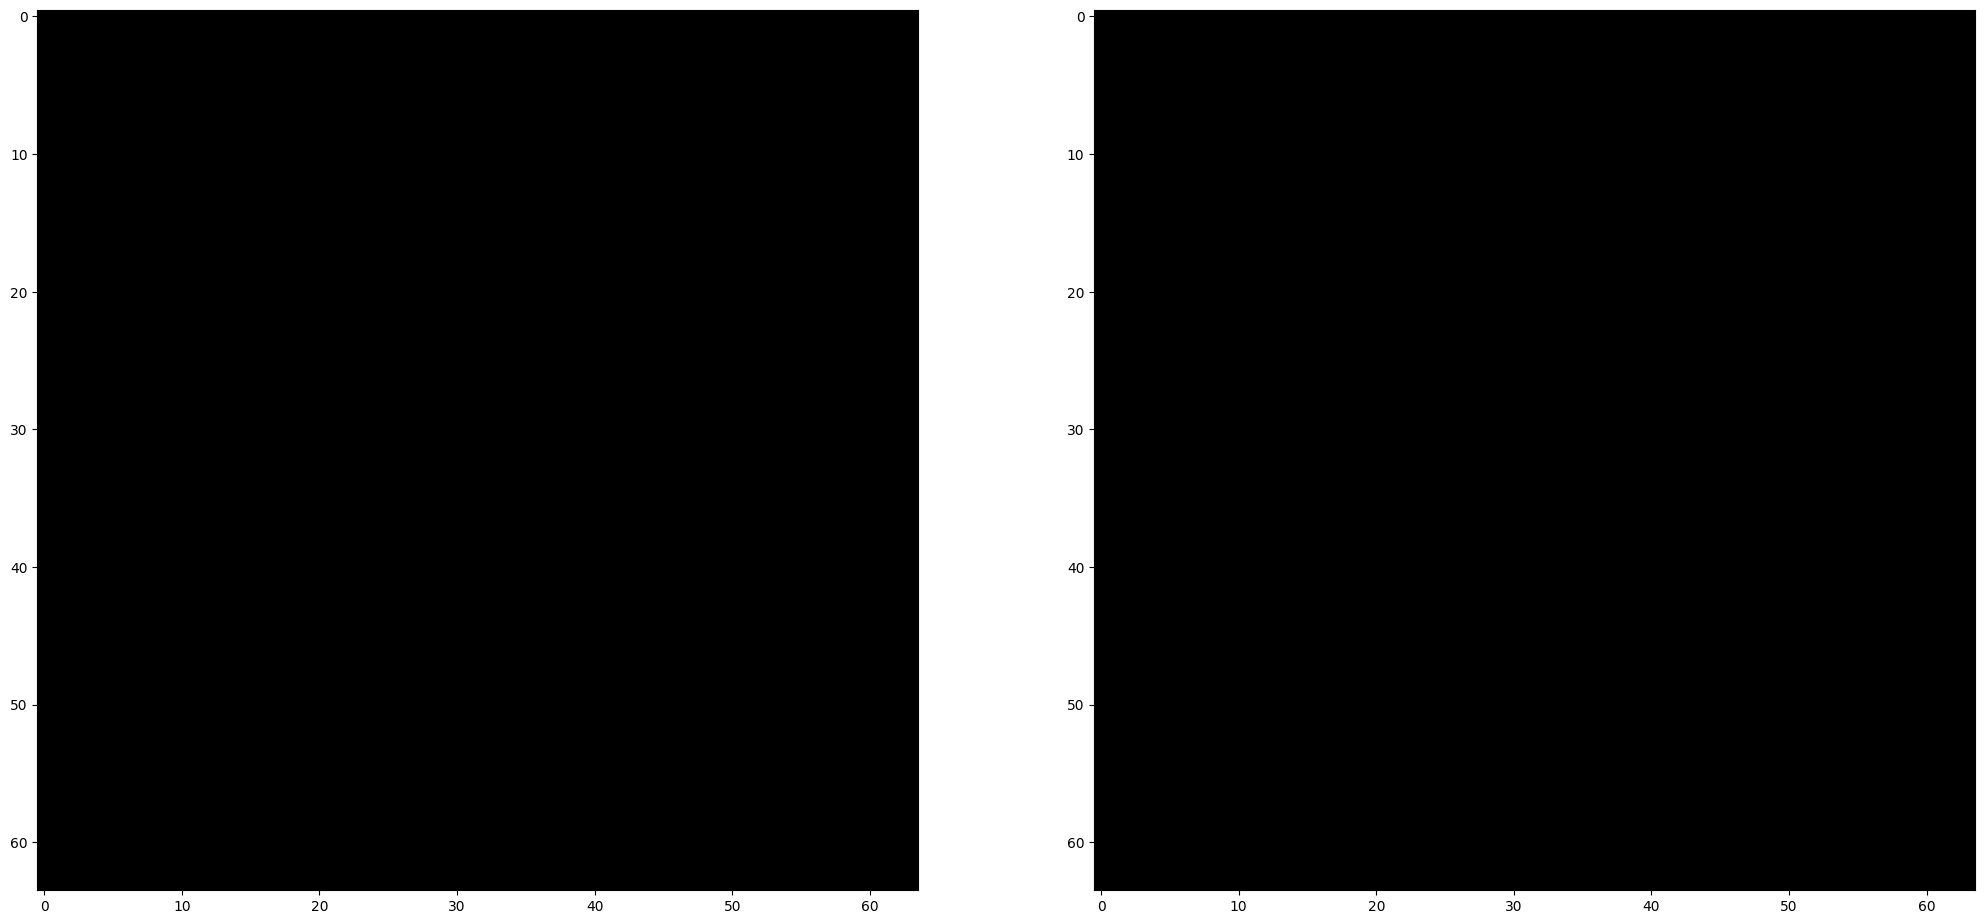

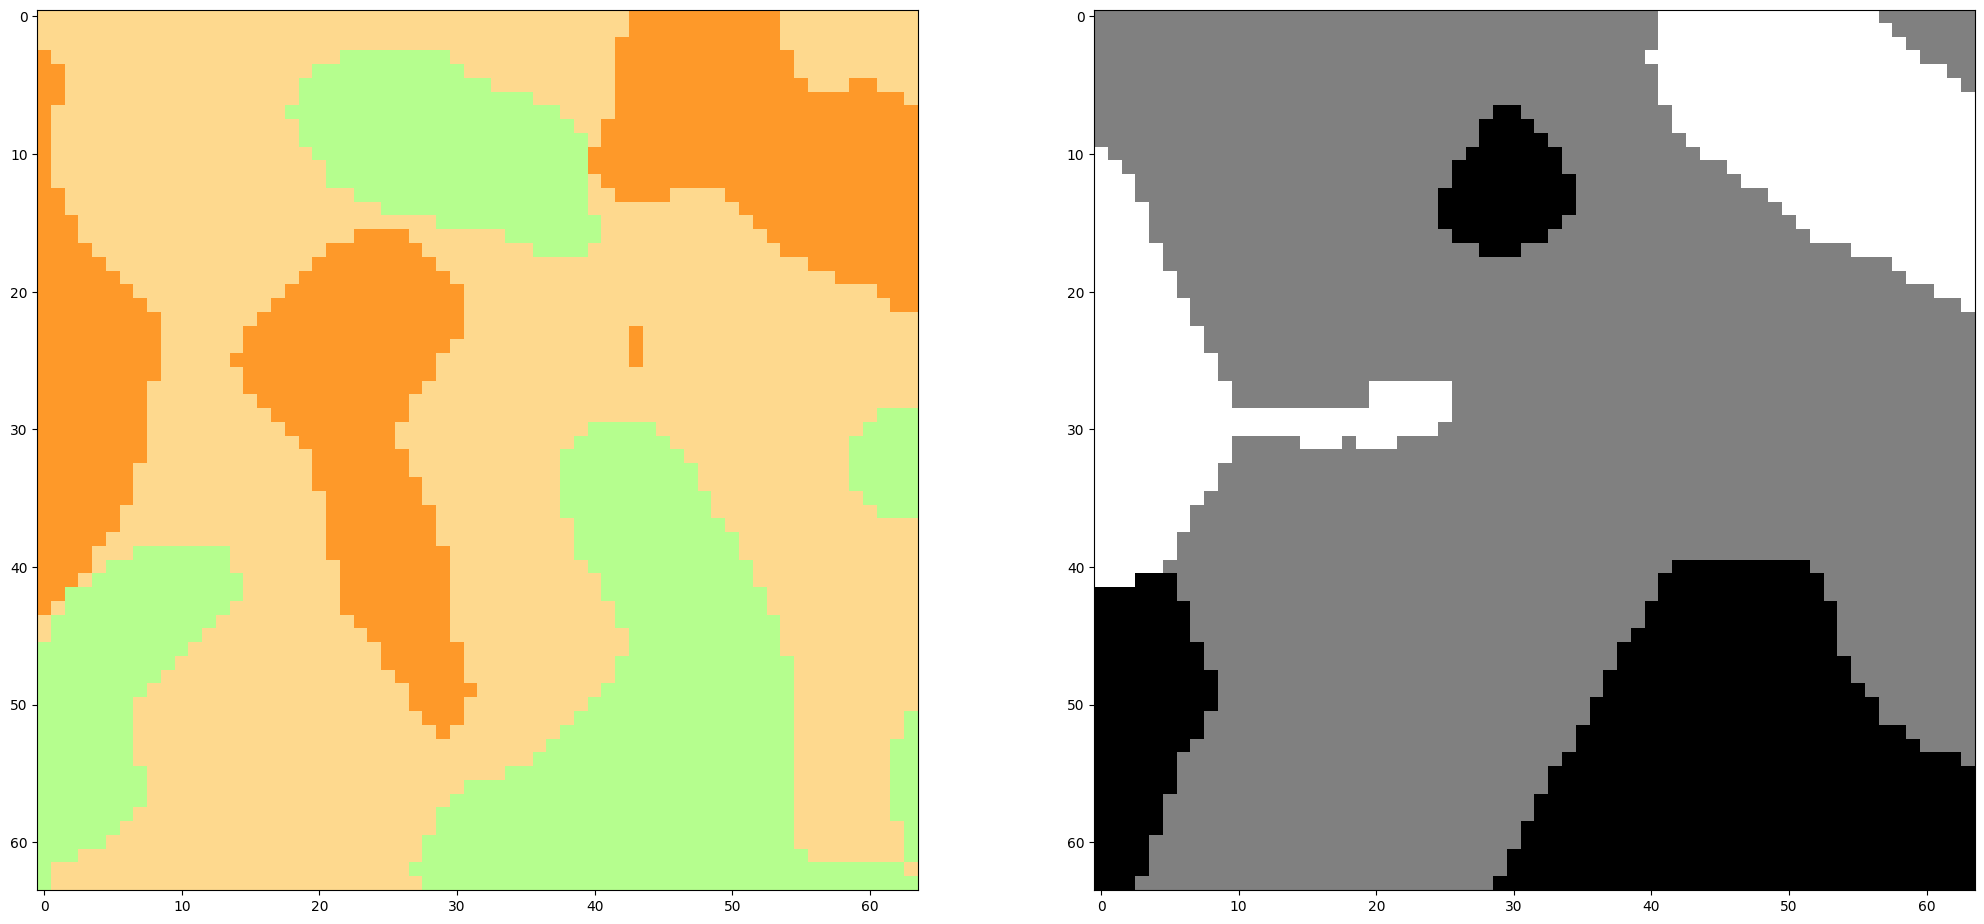

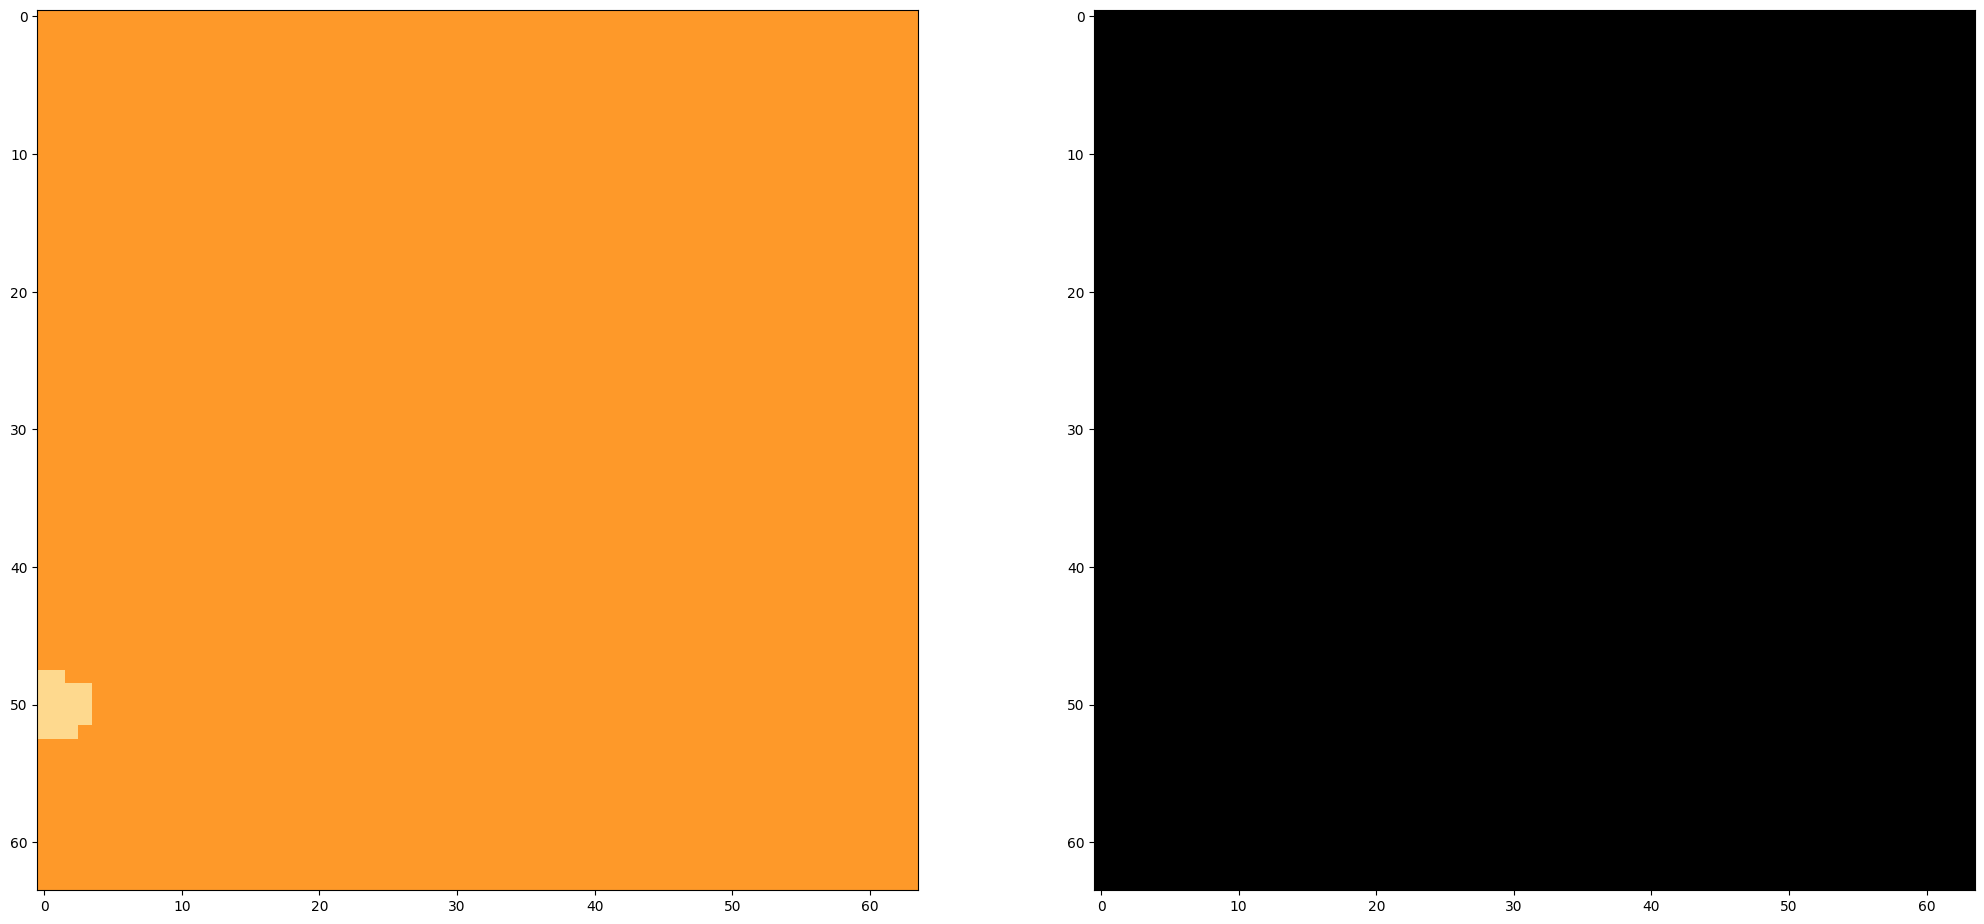

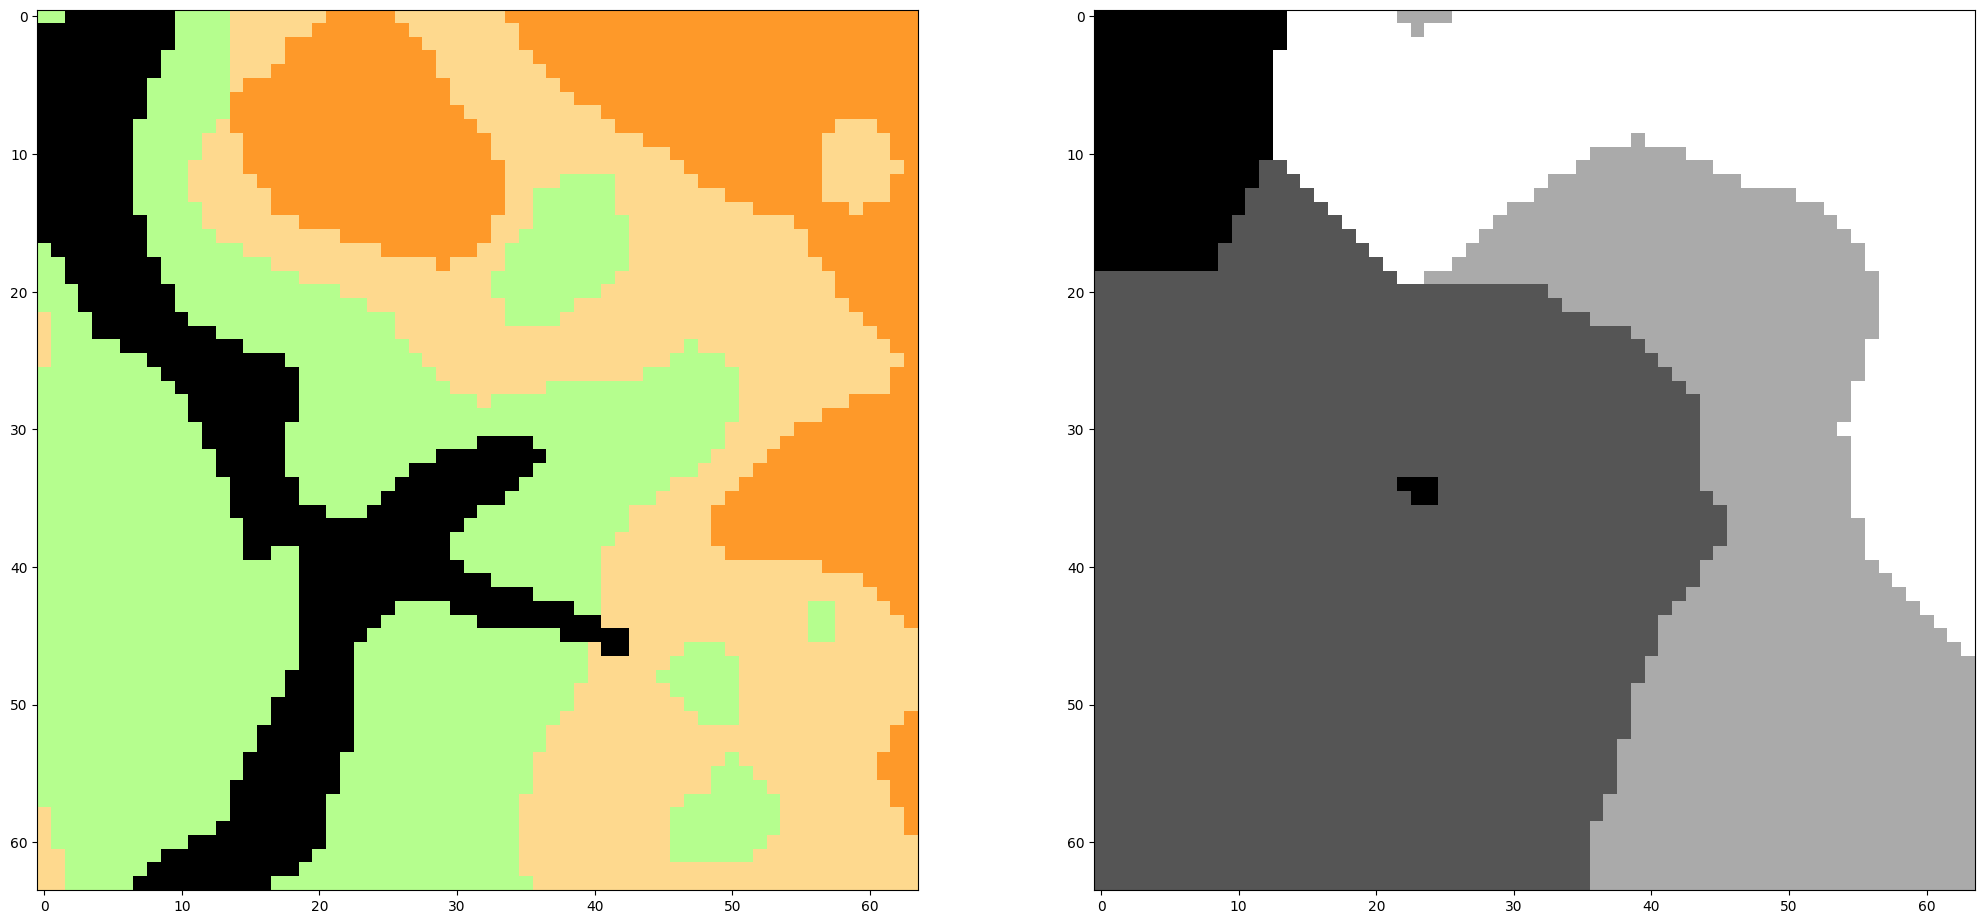

In [53]:
crop = transforms.RandomCrop(size=(64, 64))

# seed = 42

for _ in range(20):

    seed = torch.randint(0, 10000, (1,)).item()

    torch.manual_seed(seed)
    img_crop = crop(img)
    torch.manual_seed(seed)
    tensor_crop = crop(tensor)

    tensor_crop = mode_filter(tensor_crop.unsqueeze(0), kernel_size=21).squeeze(0)

    plt.figure(figsize=(25, 20))
    plt.subplot(1, 2, 1)
    plt.imshow(img_crop)
    plt.subplot(1, 2, 2)
    plt.imshow(tensor_crop.cpu().detach().numpy(), cmap='gray')
plt.show()